In [1]:
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"CUDA Version: {torch.version.cuda}")
print(f"GPU Name: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.5.1+cu121
CUDA Available: True
CUDA Version: 12.1
GPU Name: NVIDIA RTX A4000


In [2]:
# ============================================================
# Step 1: Environment, Imports, Reproducibility, and Runtime Setup
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti
# Target Dataset: KITTI
# Optimization Mode: VRAM-Armored Mixed Precision Fine-Tuning
# ============================================================

import os
import gc
import math
import glob
import time
import random
import warnings
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.metrics import confusion_matrix
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from torch.utils.data import Dataset, DataLoader
from torch.amp import GradScaler, autocast
from torch.utils.checkpoint import checkpoint 

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42

def set_seed(seed: int = 42, deterministic: bool = False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True)
        except Exception:
            pass
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

set_seed(SEED, deterministic=False)

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

%matplotlib inline
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")
sns.set_context("talk", font_scale=0.9)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
    try:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    except Exception:
        pass

PHYSICAL_BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8  
USE_AMP = torch.cuda.is_available()
scaler = GradScaler("cuda" if torch.cuda.is_available() else "cpu", enabled=USE_AMP)

DATASET_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/KITTI/training")
IMG_ROOT = DATASET_ROOT / "image_2"
MASK_ROOT = DATASET_ROOT / "semantic"

FINAL_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export") 
QUAL_VIS_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/training_visuals")

CHECKPOINT_DIR = FINAL_SAVE_DIR / "progressive_checkpoints_sgdw_v2_kitti"
PLOTS_DIR = FINAL_SAVE_DIR / "training_plots_sgdw_v2_kitti"
LOGS_DIR = FINAL_SAVE_DIR / "training_logs_sgdw_v2_kitti"
METRICS_DIR = FINAL_SAVE_DIR / "training_metrics_sgdw_v2_kitti"

for directory in [CHECKPOINT_DIR, PLOTS_DIR, LOGS_DIR, METRICS_DIR, FINAL_SAVE_DIR, QUAL_VIS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "facebook/mask2former-swin-small-cityscapes-semantic"
MODEL_ALIAS = "Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small"

history = {
    "epoch": [],
    "phase": [],
    "train_total_loss": [],
    "train_boundary_loss": [], 
    "train_miou": [],    
    "train_macc": [],    
    "train_aacc": [],    
    "val_total_loss": [],
    "val_miou": [],
    "val_macc": [],
    "val_aacc": [],
    "backbone_lr": [],
    "head_lr": [],
    "sgdw_offset_magnitude": [], 
    "sgdw_dynamic_bound": [],    
    "epoch_time_sec": [],
    "total_training_time_str": []
}

best_record = {
    "epoch": -1,
    "best_epoch": -1,
    "best_miou": -1.0,
    "best_macc": -1.0,
    "best_aacc": -1.0,
    "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_kitti.pt"),
    "latest_path": str(CHECKPOINT_DIR / "latest_model_sgdw_kitti.pt")
}

def save_checkpoint(epoch, model, optimizer_backbone, optimizer_head, scaler, scheduler, history_dict, total_time, is_best=False):
    state = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_backbone_state_dict': optimizer_backbone.state_dict(),
        'optimizer_head_state_dict': optimizer_head.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'scheduler_state_dict': scheduler.state_dict() if scheduler else None,
        'history': history_dict,
        'total_training_time': total_time,
        'best_record': best_record
    }
    
    torch.save(state, best_record['latest_path'])
    
    if is_best:
        torch.save(state, best_record['best_path'])

Device: cuda
GPU: NVIDIA RTX A4000
CUDA Version: 12.1
GPU Memory: 15.73 GB


In [8]:
# ============================================================
# STEP 2: PATHS, HYPERPARAMETERS, LABEL ENCODING, VISUALIZATION
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti
# Target Dataset: KITTI
# ============================================================

from pathlib import Path
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import pandas as pd
import torch
import torch.nn.functional as F

print(f"Image root: {IMG_ROOT}")
print(f"Mask root : {MASK_ROOT}")
print(f"Training visualizations will be saved to: {QUAL_VIS_DIR.resolve()}")
print(f"Final exported results will be saved to: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# CORE TASK SETTINGS (KITTI uses Cityscapes 19-Class standard)
# ------------------------------------------------------------
CLASSES = 19
IGNORE_INDEX = 255
USE_LABEL_TRAINIDS = True

CLASS_NAMES = [
    "Road", "Sidewalk", "Building", "Wall", "Fence", "Pole",
    "Traffic Light", "Traffic Sign", "Vegetation", "Terrain", "Sky",
    "Person", "Rider", "Car", "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

CITYSCAPES_PALETTE = np.array([
    [128, 64, 128],   # Road
    [244, 35, 232],   # Sidewalk
    [70, 70, 70],     # Building
    [102, 102, 156],  # Wall
    [190, 153, 153],  # Fence
    [153, 153, 153],  # Pole
    [250, 170, 30],   # Traffic Light
    [220, 220, 0],    # Traffic Sign
    [107, 142, 35],   # Vegetation
    [152, 251, 152],  # Terrain
    [70, 130, 180],   # Sky
    [220, 20, 60],    # Person
    [255, 0, 0],      # Rider
    [0, 0, 142],      # Car
    [0, 0, 70],       # Truck
    [0, 60, 100],     # Bus
    [0, 80, 100],     # Train
    [0, 0, 230],      # Motorcycle
    [119, 11, 32]     # Bicycle
], dtype=np.uint8)

# ------------------------------------------------------------
# IMAGE GEOMETRY (Adapted for KITTI ultra-wide aspect ratio)
# ------------------------------------------------------------
IMG_H = 384
IMG_W = 1248
VAL_IMG_H = 384
VAL_IMG_W = 1248

# ------------------------------------------------------------
# BATCHING AND EPOCHS (Hardware Optimized for RTX A4000 16GB)
# ------------------------------------------------------------
BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8    
EPOCHS = 120 
USE_EARLY_STOPPING = False  

# ------------------------------------------------------------
# TRIPARTITE SGDW OPTIMIZATION SCHEDULE
# ------------------------------------------------------------
BASE_HEAD_LR = 1e-4        
BACKBONE_LR = 1e-5         
SGDW_OFFSET_LR = 1e-5     

WARMUP_EPOCHS = 3         
WEIGHT_DECAY = 0.05       
GRAD_CLIP_NORM = 0.01     

print("\n--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---")
print(f"Total Training Epochs: {EPOCHS}")
print(f"Linear Warmup Period  : {WARMUP_EPOCHS} Epochs")
print(f"Decoder Head LR       : {BASE_HEAD_LR}")
print(f"Swin Backbone LR      : {BACKBONE_LR}")
print(f"SGDW Offset Net LR    : {SGDW_OFFSET_LR}")

# ------------------------------------------------------------
# VALIDATION / INFERENCE SETTINGS
# ------------------------------------------------------------
USE_SLIDING_WINDOW_VAL = False 
VAL_WINDOW_SIZE = (384, 1248)
VAL_WINDOW_STRIDE = (384, 1248)   
USE_FLIP_TTA = True              

# ------------------------------------------------------------
# SCHEDULER / LOSS SETTINGS
# ------------------------------------------------------------
DICE_WEIGHT = 5.0
MASK_WEIGHT = 5.0
CE_WEIGHT = 2.0

USE_BOUNDARY_LOSS = True
BOUNDARY_LOSS_WEIGHT = 0.25 

# ------------------------------------------------------------
# 34 -> 19 LABEL MAPPING & ENCODING
# ------------------------------------------------------------
mapping_34_to_19 = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255, 6: 255,
    7: 0, 8: 1, 9: 255, 10: 255, 11: 2, 12: 3, 13: 4,
    14: 255, 15: 255, 16: 255, 17: 5, 18: 255, 19: 6, 20: 7,
    21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14,
    28: 15, 29: 255, 30: 255, 31: 16, 32: 17, 33: 18, -1: 255
}

LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for k, v in mapping_34_to_19.items():
    if 0 <= k <= 255:
        LABEL_LUT[k] = v

def encode_mask(mask: np.ndarray) -> np.ndarray:
    uniq = np.unique(mask)
    if uniq.max() <= 255 and np.all(np.isin(uniq, list(range(CLASSES)) + [IGNORE_INDEX])):
        return mask.astype(np.uint8)
    encoded = LABEL_LUT[mask.clip(0, 255)]
    return encoded.astype(np.uint8)

def decode_segmap(segmentation_map: np.ndarray) -> np.ndarray:
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < CLASSES)
    for label, color in enumerate(CITYSCAPES_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

# ------------------------------------------------------------
# PUBLICATION-READY EVALUATION CURVES
# ------------------------------------------------------------
def plot_training_curves(history_dict, save_path=FINAL_SAVE_DIR):
    keys_to_extract = ['epoch', 'train_total_loss', 'val_total_loss', 'train_miou', 'val_miou']
    safe_dict = {}
    
    target_len = len(history_dict.get('epoch', []))
    if target_len == 0: return

    for k in keys_to_extract:
        if k in history_dict:
            col = history_dict[k]
            if len(col) > target_len:
                safe_dict[k] = col[:target_len]
            elif len(col) < target_len:
                safe_dict[k] = col + [np.nan] * (target_len - len(col))
            else:
                safe_dict[k] = col
        else:
            safe_dict[k] = [np.nan] * target_len

    df = pd.DataFrame(safe_dict)

    interval_df = df[(df['epoch'] % 5 == 0) | (df['epoch'] == df['epoch'].max())]
    epochs_filtered = interval_df['epoch'].values

    sns.set_theme(style="darkgrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].plot(epochs_filtered, interval_df["train_total_loss"], marker='o', label='Train Loss', color='blue', linewidth=2)
    if not interval_df["val_total_loss"].isna().all():
        axes[0].plot(epochs_filtered, interval_df["val_total_loss"], marker='s', label='Validation Loss', color='red', linewidth=2)
    axes[0].set_title('Loss Progress', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[0].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[0].legend(fontsize=12)

    axes[1].plot(epochs_filtered, interval_df["train_miou"] * 100, marker='o', label='Train mIoU', color='green', linewidth=2)
    if not interval_df["val_miou"].isna().all():
        axes[1].plot(epochs_filtered, interval_df["val_miou"] * 100, marker='s', label='Validation mIoU', color='orange', linewidth=2)
    
    axes[1].set_title('mIoU Progress (5-Epoch Intervals)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('mIoU', fontsize=12)
    
    axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[1].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[1].legend(fontsize=12)

    plt.tight_layout()
    
    combined_graph_path = Path(save_path) / "presentation_metrics_progress_sgdw_kitti.png"
    plt.savefig(combined_graph_path, dpi=600, bbox_inches="tight")
    plt.close()

# ------------------------------------------------------------
# QUALITATIVE VISUALIZATION
# ------------------------------------------------------------
def visualize_results(loader, model, epoch, save_path=QUAL_VIS_DIR, max_images=3):
    save_path = Path(save_path)
    save_path.mkdir(parents=True, exist_ok=True)
    model.eval()

    batch = next(iter(loader))
    images, mask_labels, class_labels = batch
    images = images.to(DEVICE)
    _, _, current_h, current_w = images.shape

    with torch.no_grad():
        with torch.autocast(device_type="cuda", enabled=(torch.cuda.is_available() and images.is_cuda)):
            outputs = model(pixel_values=images)
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(current_h, current_w), mode="bilinear", align_corners=False)
            mask_cls = outputs.class_queries_logits.softmax(dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            preds = torch.argmax(semantic_logits, dim=1).cpu().numpy()

    images_np = images.detach().cpu().numpy()
    targets = np.full((len(images_np), current_h, current_w), IGNORE_INDEX, dtype=np.uint8)

    for batch_idx in range(len(class_labels)):
        for inst_idx, class_id in enumerate(class_labels[batch_idx]):
            cls_id = int(class_id.item())
            if cls_id != IGNORE_INDEX and 0 <= cls_id < CLASSES:
                instance_mask = mask_labels[batch_idx][inst_idx].cpu().numpy() == 1
                targets[batch_idx][instance_mask] = cls_id

    n = min(max_images, len(images_np))
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
    if n == 1: axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img = np.transpose(images_np[i], (1, 2, 0))
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(decode_segmap(targets[i]))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(decode_segmap(preds[i]))
        axes[i, 2].set_title(f"SGDW Prediction (Epoch {epoch})")
        axes[i, 2].axis("off")

    plt.tight_layout()
    out_file = save_path / f"epoch_{epoch:03d}_comparison.png"
    plt.savefig(out_file, dpi=600, bbox_inches="tight")
    plt.close(fig)

def save_visuals_every_10_epochs(epoch, loader, model, save_path=QUAL_VIS_DIR, max_images=3):
    if epoch % 10 == 0:
        visualize_results(loader, model, epoch, save_path, max_images)

# ------------------------------------------------------------
# QUICK DATA DISCOVERY
# ------------------------------------------------------------
train_imgs = sorted(list(IMG_ROOT.glob("*.png")))
train_masks = sorted(list(MASK_ROOT.glob("*.png")))

print(f"Discovered {len(train_imgs)} images and {len(train_masks)} masks.")
print("Step 2 fully configured and optimized for SGDW Architecture.")

Image root: /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/KITTI/training/image_2
Mask root : /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/KITTI/training/semantic
Training visualizations will be saved to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/training_visuals
Final exported results will be saved to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export

--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---
Total Training Epochs: 120
Linear Warmup Period  : 3 Epochs
Decoder Head LR       : 0.0001
Swin Backbone LR      : 1e-05
SGDW Offset Net LR    : 1e-05
Discovered 200 images and 200 masks.
Step 2 fully configured and optimized for SGDW Architecture.


In [9]:
# ============================================================
# STEP 3: DATASET AND DATALOADERS
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti
# Target Dataset: KITTI
# ============================================================

import inspect
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import os
import random

# ------------------------------------------------------------
# DYNAMIC TRAIN/VAL SPLIT FOR KITTI
# ------------------------------------------------------------
all_imgs = sorted(list(IMG_ROOT.glob("*.png")))
all_masks = [MASK_ROOT / img.name for img in all_imgs]

valid_imgs = []
valid_masks = []
for img_path, mask_path in zip(all_imgs, all_masks):
    if mask_path.exists():
        valid_imgs.append(img_path)
        valid_masks.append(mask_path)

if len(valid_imgs) == 0:
    raise FileNotFoundError(f"No valid image/mask pairs found in {IMG_ROOT} and {MASK_ROOT}")

np.random.seed(SEED)
indices = np.random.permutation(len(valid_imgs))
split_idx = int(len(valid_imgs) * 0.8)

train_img_paths = [valid_imgs[i] for i in indices[:split_idx]]
train_mask_paths = [valid_masks[i] for i in indices[:split_idx]]

val_img_paths = [valid_imgs[i] for i in indices[split_idx:]]
val_mask_paths = [valid_masks[i] for i in indices[split_idx:]]

print(f"\n--- KITTI Dataset Split ---")
print(f"Total valid images : {len(valid_imgs)}")
print(f"Training images    : {len(train_img_paths)}")
print(f"Validation images  : {len(val_img_paths)}")

# ------------------------------------------------------------
# KITTI 34 -> 19 CLASS MAPPING
# ------------------------------------------------------------
mapping_34_to_19 = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255, 6: 255,
    7: 0, 8: 1, 9: 255, 10: 255, 11: 2, 12: 3, 13: 4,
    14: 255, 15: 255, 16: 255, 17: 5, 18: 255, 19: 6, 20: 7,
    21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14,
    28: 15, 29: 255, 30: 255, 31: 16, 32: 17, 33: 18, -1: 255
}

LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for k, v in mapping_34_to_19.items():
    if 0 <= k <= 255:
        LABEL_LUT[k] = v

def encode_mask(mask: np.ndarray) -> np.ndarray:
    uniq = np.unique(mask)
    if uniq.max() <= 255 and np.all(np.isin(uniq, list(range(CLASSES)) + [IGNORE_INDEX])):
        return mask.astype(np.uint8)
    encoded = LABEL_LUT[mask.clip(0, 255)]
    return encoded.astype(np.uint8)

# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------
class KITTIDataset(Dataset):
    def __init__(self, image_paths, mask_paths, split="train", transform=None, rare_class_ids=None, rare_retry_count=0):
        self.transform = transform
        self.split = split
        self.rare_class_ids = rare_class_ids if rare_class_ids is not None else []
        self.rare_retry_count = rare_retry_count
        self.images = image_paths
        self.masks = mask_paths

        assert len(self.images) == len(self.masks), "Image/mask length mismatch"

    def __len__(self):
        return len(self.images)

    def _load_raw(self, idx):
        img_path = str(self.images[idx])
        mask_path = str(self.masks[idx])

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if image is None:
            raise FileNotFoundError(f"cv2.imread failed for image: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise FileNotFoundError(f"cv2.imread failed for mask: {mask_path}")

        mask = encode_mask(mask)
        return image, mask

    def _contains_rare_class(self, mask):
        if len(self.rare_class_ids) == 0:
            return False
        unique_ids = np.unique(mask)
        return any(cls_id in unique_ids for cls_id in self.rare_class_ids)

    def __getitem__(self, idx):
        image, mask = self._load_raw(idx)

        if self.transform is not None:
            if self.split == "train" and self.rare_retry_count > 0:
                selected_aug = None
                for attempt in range(self.rare_retry_count):
                    augmented = self.transform(image=image, mask=mask)
                    aug_mask = augmented["mask"]
                    aug_mask_np = aug_mask.cpu().numpy() if torch.is_tensor(aug_mask) else aug_mask

                    if self._contains_rare_class(aug_mask_np):
                        selected_aug = augmented
                        break
                    selected_aug = augmented 

                augmented = selected_aug
            else:
                augmented = self.transform(image=image, mask=mask)

            image = augmented["image"]
            mask = augmented["mask"]

        if not torch.is_tensor(image):
            image = torch.as_tensor(image).permute(2, 0, 1).float()
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(mask, dtype=torch.long)
        else:
            mask = mask.long()

        unique_labels = torch.unique(mask)
        unique_labels = unique_labels[unique_labels != IGNORE_INDEX]

        if unique_labels.numel() == 0:
            class_labels = torch.empty((0,), dtype=torch.long)
            mask_labels = torch.empty((0, mask.shape[0], mask.shape[1]), dtype=torch.float32)
        else:
            class_labels = unique_labels.long()
            mask_labels = (mask.unsqueeze(0) == class_labels[:, None, None]).float()

        return image, mask_labels, class_labels

# ------------------------------------------------------------
# AUGMENTATION HELPERS & TRANSFORMS
# ------------------------------------------------------------
def pad_if_needed_tf(min_h, min_w, ignore_index=255):
    sig = inspect.signature(A.PadIfNeeded)
    kwargs = dict(min_height=min_h, min_width=min_w, border_mode=cv2.BORDER_CONSTANT, p=1.0)
    if "fill" in sig.parameters:
        kwargs.update(fill=0, fill_mask=ignore_index)
    else:
        kwargs.update(value=0, mask_value=ignore_index)
    return A.PadIfNeeded(**kwargs)

train_transform = A.Compose([
    A.RandomScale(scale_limit=(-0.5, 1.0), interpolation=cv2.INTER_LINEAR, p=1.0), 
    pad_if_needed_tf(IMG_H, IMG_W, IGNORE_INDEX),
    A.RandomCrop(height=IMG_H, width=IMG_W, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.3),
    A.GaussianBlur(blur_limit=(3, 3), p=0.1),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

val_transform = A.Compose([
    pad_if_needed_tf(VAL_IMG_H, VAL_IMG_W, IGNORE_INDEX),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# ------------------------------------------------------------
# COLLATE FUNCTION
# ------------------------------------------------------------
def mask2former_collate_fn(batch):
    images = torch.stack([item[0] for item in batch], dim=0)
    mask_labels = [item[1] for item in batch]
    class_labels = [item[2] for item in batch]
    return images, mask_labels, class_labels

# ------------------------------------------------------------
# INITIALIZATION
# ------------------------------------------------------------
USE_RARE_CLASS_AWARE_SAMPLING = True
RARE_CLASS_IDS = [3, 4, 5, 6, 7, 9, 12, 17, 18]

rare_retry_count = 4 if USE_RARE_CLASS_AWARE_SAMPLING else 0

train_dataset = KITTIDataset(
    image_paths=train_img_paths, mask_paths=train_mask_paths, split="train",
    transform=train_transform, rare_class_ids=RARE_CLASS_IDS, rare_retry_count=rare_retry_count
)

val_dataset = KITTIDataset(
    image_paths=val_img_paths, mask_paths=val_mask_paths, split="val",
    transform=val_transform, rare_class_ids=None, rare_retry_count=0
)

NUM_WORKERS = min(4, os.cpu_count() if os.cpu_count() is not None else 2)
PIN_MEMORY = torch.cuda.is_available()
PERSISTENT_WORKERS = NUM_WORKERS > 0

print(f"\n--- DataLoader Hardware Configuration ---")
print(f"Num workers         : {NUM_WORKERS}")
print(f"Pin memory          : {PIN_MEMORY}")
print(f"Persistent workers  : {PERSISTENT_WORKERS}")
print(f"Rare retry count    : {rare_retry_count}")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=True,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------
train_batch = next(iter(train_loader))
train_images, train_mask_labels, train_class_labels = train_batch

print("\n--- Train Batch Sanity Check ---")
print(f"Images shape              : {train_images.shape}")
print(f"Sample 0 num segments     : {train_mask_labels[0].shape[0]}")
print(f"Sample 0 mask tensor shape: {train_mask_labels[0].shape}")

val_batch = next(iter(val_loader))
val_images, val_mask_labels, val_class_labels = val_batch

assert train_images.shape[-2:] == (IMG_H, IMG_W), f"Expected train crop {IMG_H}x{IMG_W}, got {train_images.shape[-2:]}"
assert val_images.shape[-2:] == (VAL_IMG_H, VAL_IMG_W), f"Expected val crop {VAL_IMG_H}x{VAL_IMG_W}, got {val_images.shape[-2:]}"

print("\nStep 3 configured successfully and ready to feed the SGDW model.")


--- KITTI Dataset Split ---
Total valid images : 200
Training images    : 160
Validation images  : 40

--- DataLoader Hardware Configuration ---
Num workers         : 4
Pin memory          : True
Persistent workers  : True
Rare retry count    : 4

--- Train Batch Sanity Check ---
Images shape              : torch.Size([2, 3, 384, 1248])
Sample 0 num segments     : 14
Sample 0 mask tensor shape: torch.Size([14, 384, 1248])

Step 3 configured successfully and ready to feed the SGDW model.


In [10]:
# ============================================================
# STEP 4: MODEL, PHASE MANAGEMENT, LOSS, OPTIMIZER, SCHEDULER
# For: WEPD-Mask2Former (Wavelet-Enhanced Pixel Decoder)
# Target Dataset: KITTI
# ============================================================

import os
import math
import warnings
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from transformers import Mask2FormerForUniversalSegmentation

# ------------------------------------------------------------
# SAFETY CHECKS
# ------------------------------------------------------------
if "train_loader" not in globals():
    raise NameError("train_loader is not defined. Please run Step 3 first.")

if "DEVICE" not in globals():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if "CLASSES" not in globals():
    CLASSES = 19

if "CLASS_NAMES" not in globals():
    CLASS_NAMES = [
        "Road", "Sidewalk", "Building", "Wall", "Fence", "Pole",
        "Traffic Light", "Traffic Sign", "Vegetation", "Terrain", "Sky",
        "Person", "Rider", "Car", "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
    ]

if "IGNORE_INDEX" not in globals():
    IGNORE_INDEX = 255

# ------------------------------------------------------------
# HYPERPARAMETERS FROM STEP 2
# ------------------------------------------------------------
WEIGHT_DECAY = globals().get("WEIGHT_DECAY", 0.01)
GRAD_CLIP_NORM = globals().get("GRAD_CLIP_NORM", 1.0)

PHASE1_END_EPOCH = globals().get("PHASE1_END_EPOCH", 5)
PHASE2_END_EPOCH = globals().get("PHASE2_END_EPOCH", 80)

PHASE1_HEAD_LR = globals().get("PHASE1_HEAD_LR", 6e-5)
PHASE2_BACKBONE_LR = globals().get("PHASE2_BACKBONE_LR", 4e-6)
PHASE2_HEAD_LR = globals().get("PHASE2_HEAD_LR", 4e-5)

WARMUP_EPOCHS = globals().get("WARMUP_EPOCHS", 3)

USE_FOCAL_LOSS = globals().get("USE_FOCAL_LOSS", True)
FOCAL_GAMMA = globals().get("FOCAL_GAMMA", 2.0)
FOCAL_WEIGHT = globals().get("FOCAL_WEIGHT", 1.0)

USE_LOVASZ = globals().get("USE_LOVASZ", True)
LOVASZ_WEIGHT = globals().get("LOVASZ_WEIGHT", 0.5)

USE_BOUNDARY_LOSS = globals().get("USE_BOUNDARY_LOSS", True)
BOUNDARY_LOSS_WEIGHT = globals().get("BOUNDARY_LOSS_WEIGHT", 0.25)

FREEZE_BATCHNORM_STATS = globals().get("FREEZE_BATCHNORM_STATS", True)

USE_AMP = globals().get("USE_AMP", torch.cuda.is_available())
scaler = globals().get(
    "scaler",
    torch.amp.GradScaler("cuda" if torch.cuda.is_available() else "cpu", enabled=USE_AMP)
)

GRAD_ACCUM_STEPS = globals().get("GRAD_ACCUM_STEPS", 4)
EPOCHS = globals().get("EPOCHS", 80)

# ------------------------------------------------------------
# LABEL MAPS & HF SETUP
# ------------------------------------------------------------
id2label = {i: CLASS_NAMES[i] for i in range(CLASSES)}
label2id = {v: k for k, v in id2label.items()}
HF_TOKEN = os.environ.get("HF_TOKEN", None)

if HF_TOKEN is None:
    warnings.filterwarnings("ignore", message=".*unauthenticated requests to the HF Hub.*")

# ------------------------------------------------------------
# LOAD PRETRAINED MODEL
# ------------------------------------------------------------
MODEL_NAME = globals().get("MODEL_NAME", "facebook/mask2former-swin-small-cityscapes-semantic")
MODEL_ALIAS = globals().get("MODEL_ALIAS", "WEPD-Mask2Former + Swin-Small")

load_kwargs = dict(
    pretrained_model_name_or_path=MODEL_NAME,
    num_labels=CLASSES,
    ignore_mismatched_sizes=True,
    id2label=id2label,
    label2id=label2id,
)

if HF_TOKEN is not None:
    load_kwargs["token"] = HF_TOKEN

model = Mask2FormerForUniversalSegmentation.from_pretrained(**load_kwargs).to(DEVICE)
print(f"Loaded base model: {MODEL_NAME}")

def freeze_norm_layers(module: torch.nn.Module):
    norm_types = (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d, torch.nn.BatchNorm3d, torch.nn.SyncBatchNorm)
    for m in module.modules():
        if isinstance(m, norm_types):
            m.eval()
            for p in m.parameters():
                p.requires_grad = False

if FREEZE_BATCHNORM_STATS:
    freeze_norm_layers(model)

# ============================================================
# ARCHITECTURAL NOVELTY: WEPD (Wavelet-Enhanced Pixel Decoder)
# ============================================================
class WaveletGatingModule(nn.Module):
    """
    Extracts high-frequency spatial components (horizontal, vertical, diagonal edges) 
    using deterministic convolutions approximating 2D high-pass wavelet filters,
    and applies a lightweight MLP to generate a Boundary Confidence Map.
    """
    def __init__(self, channels):
        super().__init__()
        self.channels = channels
        
        self.high_pass = nn.Conv2d(channels, channels * 3, kernel_size=3, stride=1, padding=1, groups=channels, bias=False)
        
        weight = torch.zeros((channels * 3, 1, 3, 3))
        h_edge = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32) / 4.0
        v_edge = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32) / 4.0
        d_edge = torch.tensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=torch.float32) / 4.0
        
        for i in range(channels):
            weight[i*3 + 0, 0] = h_edge
            weight[i*3 + 1, 0] = v_edge
            weight[i*3 + 2, 0] = d_edge
            
        self.high_pass.weight = nn.Parameter(weight, requires_grad=False)
        
        mid_channels = max(16, channels // 4)
        self.gate = nn.Sequential(
            nn.Conv2d(channels * 3, mid_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.GELU(),
            nn.Conv2d(mid_channels, channels, kernel_size=1, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        hf_feats = self.high_pass(x)
        confidence_map = self.gate(hf_feats)
        return x * confidence_map + x

class SwinWEPDWrapper(nn.Module):
    """
    Wraps the Swin encoder to intercept spatial grids, apply the 
    Wavelet-Enhanced gating mechanism, and pass strictly defined edges 
    downstream to the Mask2Former Pixel Decoder.
    """
    def __init__(self, original_encoder):
        super().__init__()
        self.encoder = original_encoder
        self.wepd_blocks = nn.ModuleList([WaveletGatingModule(c) for c in [96, 192, 384, 768]])

    def forward(self, *args, **kwargs):
        pixel_values = kwargs.get("pixel_values", args[0] if len(args) > 0 else None)
        img_H, img_W = (384, 1248) 
        if pixel_values is not None and torch.is_tensor(pixel_values):
            img_H, img_W = pixel_values.shape[-2:]

        kwargs["output_hidden_states"] = True
        outputs = self.encoder(*args, **kwargs)
        
        if hasattr(outputs, 'hidden_states'):
            new_hidden = []
            for i, h in enumerate(outputs.hidden_states):
                if h.dim() == 3: 
                    B, L, C = h.shape
                    factor = 4 * (2 ** i)
                    feat_H, feat_W = img_H // factor, img_W // factor
                    
                    if feat_H * feat_W == L:
                        h_spatial = h.transpose(1, 2).reshape(B, C, feat_H, feat_W).contiguous()
                        h_spatial = self.wepd_blocks[i](h_spatial)
                        h_seq = h_spatial.flatten(2).transpose(1, 2).contiguous()
                        new_hidden.append(h_seq)
                    else:
                        new_hidden.append(h)
                elif h.dim() == 4: 
                    new_hidden.append(self.wepd_blocks[i](h))
                else:
                    new_hidden.append(h)
                    
            outputs.hidden_states = tuple(new_hidden)
            
        return outputs

# ============================================================
# FRAMEWORK INTEGRATION
# ============================================================
class WEPDMasterWrapper(nn.Module):
    """
    Master wrapper integrating the Wavelet-Enhanced Pixel Decoder modifications.
    """
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        
        original_encoder = self.base_model.model.pixel_level_module.encoder
        self.base_model.model.pixel_level_module.encoder = SwinWEPDWrapper(original_encoder)

    def forward(self, *args, **kwargs):
        return self.base_model(*args, **kwargs)

    def refined_semantic_logits(self, outputs, target_size):
        H, W = target_size
        mask_preds = outputs.masks_queries_logits
        class_logits = outputs.class_queries_logits
        mask_preds_up = F.interpolate(mask_preds, size=(H, W), mode="bilinear", align_corners=False)
        mask_cls = F.softmax(class_logits, dim=-1)[..., :-1]
        return torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds_up.sigmoid())

model = WEPDMasterWrapper(model).to(DEVICE)

print("\nArchitectural modules successfully injected:")
print("1. WEPD (Wavelet-Enhanced Pixel Decoder) wrapped around Swin multi-scale features.")

# ------------------------------------------------------------
# LOSS FORMULATIONS
# ------------------------------------------------------------
def compute_focal_loss(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, gamma: float = 2.0, ignore_index: int = 255) -> torch.Tensor:
    ce_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=ignore_index, reduction='none')
    pt = torch.exp(-ce_loss)
    focal_loss = ((1 - pt) ** gamma) * ce_loss
    return focal_loss.mean()

def lovasz_grad(gt_sorted: torch.Tensor) -> torch.Tensor:
    p = len(gt_sorted)
    gts = gt_sorted.sum()
    intersection = gts - gt_sorted.float().cumsum(0)
    union = gts + (1 - gt_sorted).float().cumsum(0)
    jaccard = 1.0 - intersection / (union + 1e-10)
    if p > 1:
        jaccard[1:p] = jaccard[1:p] - jaccard[0:-1]
    return jaccard

def _safe_mean(losses, device):
    if len(losses) == 0: return torch.tensor(0.0, device=device, requires_grad=True)
    return sum(losses) / len(losses)

def lovasz_softmax_flat(probs: torch.Tensor, labels: torch.Tensor, classes="present") -> torch.Tensor:
    if probs.numel() == 0: return torch.tensor(0.0, device=probs.device, requires_grad=True)
    C = probs.size(1)
    losses = []
    class_to_sum = list(range(C)) if classes in ["all", "present"] else classes

    for c in class_to_sum:
        fg = (labels == c).float()
        if classes == "present" and fg.sum() == 0: continue
        class_pred = probs[:, c]
        errors = (fg - class_pred).abs()
        errors_sorted, perm = torch.sort(errors, descending=True)
        fg_sorted = fg[perm]
        losses.append(torch.dot(errors_sorted, lovasz_grad(fg_sorted)))

    return _safe_mean(losses, probs.device)

def lovasz_softmax_from_logits(logits: torch.Tensor, labels: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    probs = F.softmax(logits, dim=1)
    valid_mask = (labels != ignore_index)
    if valid_mask.sum() == 0: return torch.tensor(0.0, device=logits.device, requires_grad=True)
    probs_valid = probs.permute(0, 2, 3, 1)[valid_mask]
    labels_valid = labels[valid_mask]
    return lovasz_softmax_flat(probs_valid, labels_valid, classes="present")

def compute_boundary_map(targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    boundary = torch.zeros_like(targets, dtype=torch.bool)
    valid = (targets != ignore_index)
    boundary[:, :, 1:] |= ((targets[:, :, 1:] != targets[:, :, :-1]) & valid[:, :, 1:] & valid[:, :, :-1])
    boundary[:, 1:, :] |= ((targets[:, 1:, :] != targets[:, :-1, :]) & valid[:, 1:, :] & valid[:, :-1, :])
    return boundary.unsqueeze(1).float()

def compute_soft_boundary_map(semantic_logits: torch.Tensor) -> torch.Tensor:
    probs = F.softmax(semantic_logits.float(), dim=1)
    B, C, H, W = probs.shape
    boundary = torch.zeros((B, 1, H, W), device=probs.device, dtype=probs.dtype)

    dh = torch.abs(probs[:, :, :, 1:] - probs[:, :, :, :-1]).mean(dim=1, keepdim=True)
    boundary[:, :, :, 1:] += dh

    dv = torch.abs(probs[:, :, 1:, :] - probs[:, :, :-1, :]).mean(dim=1, keepdim=True)
    boundary[:, :, 1:, :] += dv

    return boundary.clamp(min=0.0, max=1.0)

def compute_boundary_loss(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    with torch.no_grad():
        target_boundary = compute_boundary_map(dense_targets, ignore_index=ignore_index)
    pred_boundary = compute_soft_boundary_map(semantic_logits)
    return F.smooth_l1_loss(pred_boundary, target_boundary)

def build_semantic_targets_from_instance_targets(mask_labels, class_labels, image_size, ignore_index=255):
    H, W = image_size
    batch_size = len(mask_labels)
    device = mask_labels[0].device if len(mask_labels) > 0 else DEVICE
    targets = torch.full((batch_size, H, W), fill_value=ignore_index, dtype=torch.long, device=device)

    for b in range(batch_size):
        if class_labels[b].numel() == 0: continue
        for inst_idx, cls_id in enumerate(class_labels[b]):
            cls_id = int(cls_id.item())
            if cls_id == ignore_index: continue
            targets[b][mask_labels[b][inst_idx] > 0.5] = cls_id
    return targets

def compute_metrics(conf_matrix: np.ndarray):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    return {
        "mIoU": float(mIoU), "aAcc": float(aAcc), "mAcc": float(mAcc),
        "iou_per_class": iou_per_class, "acc_per_class": acc_per_class
    }

# ------------------------------------------------------------
# HYBRID LOSS INTEGRATION
# ------------------------------------------------------------
def compute_hybrid_loss(outputs, dense_targets, model_ref):
    native_loss = outputs.loss if outputs.loss is not None else torch.tensor(0.0, device=dense_targets.device)
    H, W = dense_targets.shape[1], dense_targets.shape[2]

    semantic_logits = model_ref.refined_semantic_logits(outputs, target_size=(H, W))

    if USE_FOCAL_LOSS:
        main_loss = compute_focal_loss(semantic_logits, dense_targets, gamma=FOCAL_GAMMA, ignore_index=IGNORE_INDEX)
        main_weight = FOCAL_WEIGHT
    else:
        main_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
        main_weight = 1.0

    lovasz_loss = torch.tensor(0.0, device=dense_targets.device)
    boundary_loss = torch.tensor(0.0, device=dense_targets.device)

    if USE_LOVASZ:
        lovasz_loss = lovasz_softmax_from_logits(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)

    if USE_BOUNDARY_LOSS:
        boundary_loss = compute_boundary_loss(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)

    total_loss = native_loss + (main_weight * main_loss) + (LOVASZ_WEIGHT * lovasz_loss) \
                 + (BOUNDARY_LOSS_WEIGHT * boundary_loss)

    loss_dict = {
        "native_loss": float(native_loss.detach().item()),
        "ce_loss": float(main_loss.detach().item()),
        "lovasz_loss": float(lovasz_loss.detach().item()),
        "boundary_loss": float(boundary_loss.detach().item()),
        "total_loss": float(total_loss.detach().item())
    }

    return total_loss, loss_dict, semantic_logits

# ------------------------------------------------------------
# PHASE MANAGEMENT & OPTIMIZER
# ------------------------------------------------------------
def get_current_phase(epoch: int) -> int:
    return 1 if epoch <= PHASE1_END_EPOCH else 2

def is_backbone_param(name: str) -> bool:
    return "base_model" in name and "pixel_level_module.encoder.encoder" in name

def _set_requires_grad_by_name(model, allow_fn):
    for name, param in model.named_parameters():
        param.requires_grad = bool(allow_fn(name))

def set_model_phase(model, phase: int):
    for p in model.parameters():
        p.requires_grad = False

    if phase == 1:
        print("--- PHASE 1: Swin backbone frozen; WEPD Module + Decoder trainable ---")
        def allow_fn(name):
            if "wepd" in name:
                return True
            if "base_model" in name and "pixel_level_module.encoder.encoder" not in name:
                return True
            return False
        _set_requires_grad_by_name(model, allow_fn)

    elif phase == 2:
        print("--- PHASE 2: Top Swin stages + WEPD Module + Decoder trainable ---")
        def allow_fn(name):
            if "wepd" in name:
                return True
            if "base_model" in name and "pixel_level_module.encoder.encoder" in name:
                return any(k in name for k in ["layers.2", "layers.3", "layernorm", "norm"])
            if "base_model" in name:
                return True
            return False
        _set_requires_grad_by_name(model, allow_fn)
    else:
        raise ValueError(f"Unknown phase: {phase}")

    if FREEZE_BATCHNORM_STATS:
        freeze_norm_layers(model)

def count_trainable_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def get_optimizer_for_phase(model, phase: int):
    backbone_params = []
    head_params = []
    novelty_params = []

    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue

        if "wepd" in n:
            novelty_params.append(p)
        elif is_backbone_param(n):
            backbone_params.append(p)
        else:
            head_params.append(p)

    param_groups = []

    if phase == 1:
        if len(head_params) > 0:
            param_groups.append({"params": head_params, "lr": PHASE1_HEAD_LR})
        if len(novelty_params) > 0:
            param_groups.append({"params": novelty_params, "lr": PHASE1_HEAD_LR * 2.0})

    elif phase == 2:
        if len(backbone_params) > 0:
            param_groups.append({"params": backbone_params, "lr": PHASE2_BACKBONE_LR})
        if len(head_params) > 0:
            param_groups.append({"params": head_params, "lr": PHASE2_HEAD_LR})
        if len(novelty_params) > 0:
            param_groups.append({"params": novelty_params, "lr": PHASE2_HEAD_LR * 2.0})

    return optim.AdamW(
        param_groups,
        weight_decay=WEIGHT_DECAY,
        betas=(0.9, 0.999),
        eps=1e-8
    )

# ------------------------------------------------------------
# SCHEDULER: COSINE ANNEALING WITH LINEAR WARMUP
# ------------------------------------------------------------
def build_cosine_warmup_scheduler(optimizer, warmup_steps, total_steps):
    if warmup_steps >= total_steps:
        warmup_steps = max(1, total_steps - 1)
        
    warmup_scheduler = LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_steps)
    cosine_scheduler = CosineAnnealingLR(optimizer, T_max=(total_steps - warmup_steps), eta_min=1e-7)
    
    return SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_steps])

# ------------------------------------------------------------
# INITIALIZATION FOR PHASE 1
# ------------------------------------------------------------
current_phase = 1
set_model_phase(model, phase=current_phase)

total_params, trainable_params = count_trainable_params(model)
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

optimizer = get_optimizer_for_phase(model, current_phase)

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
total_update_steps = steps_per_epoch * EPOCHS
warmup_steps = steps_per_epoch * WARMUP_EPOCHS

scheduler = build_cosine_warmup_scheduler(optimizer, warmup_steps, total_update_steps)

print("\n--- Phase 1 Optimizer & Scheduler Initialized ---")
print(f"Main Loss Function   : {'Focal Loss (Gamma=' + str(FOCAL_GAMMA) + ')' if USE_FOCAL_LOSS else 'Cross Entropy'}")
print(f"AMP enabled          : {scaler.is_enabled()}")
print(f"Steps/epoch          : {steps_per_epoch}")
print(f"Warmup steps         : {warmup_steps}")
print(f"Total update steps   : {total_update_steps}")

print("\nStep 4 configured successfully. Ready for the main training loop.")

Loading weights:   0%|          | 0/782 [00:00<?, ?it/s]

Loaded base model: facebook/mask2former-swin-small-cityscapes-semantic

Architectural modules successfully injected:
1. WEPD (Wavelet-Enhanced Pixel Decoder) wrapped around Swin multi-scale features.
--- PHASE 1: Swin backbone frozen; WEPD Module + Decoder trainable ---
Total parameters     : 69,546,830
Trainable parameters : 20,707,508

--- Phase 1 Optimizer & Scheduler Initialized ---
Main Loss Function   : Focal Loss (Gamma=2.0)
AMP enabled          : True
Steps/epoch          : 10
Warmup steps         : 30
Total update steps   : 1200

Step 4 configured successfully. Ready for the main training loop.


Starting Training: 120 Epochs
Progressive Unfreezing: Active (Early Stopping Disabled)
Focal Loss Active: True
Boundary Loss Active: True
Validation AMP Overridden: FP32 Forced (NaN Fix Applied)



Epoch 1/120 | Phase 1 | Time: 35.45s | ETA: 1:10:19
Train Loss: 28.4159 | Train mIoU: 67.25%
Val Loss:   2.0150 | Val mIoU:   57.94% | Val aAcc:   92.56%
LR Backbone: 4.02e-05 | LR Head: 8.04e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_001.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 57.94% saved.



Epoch 2/120 | Phase 1 | Time: 34.95s | ETA: 1:13:34
Train Loss: 24.4196 | Train mIoU: 68.26%
Val Loss:   1.6421 | Val mIoU:   60.65% | Val aAcc:   91.98%
LR Backbone: 6.00e-05 | LR Head: 1.20e-04
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_002.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 60.65% saved.



Epoch 3/120 | Phase 1 | Time: 35.62s | ETA: 1:14:37
Train Loss: 23.0616 | Train mIoU: 71.97%
Val Loss:   1.7307 | Val mIoU:   62.16% | Val aAcc:   92.65%
LR Backbone: 6.00e-05 | LR Head: 1.20e-04
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_003.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 62.16% saved.



Epoch 4/120 | Phase 1 | Time: 34.59s | ETA: 1:14:18
Train Loss: 22.0284 | Train mIoU: 68.58%
Val Loss:   1.5356 | Val mIoU:   59.59% | Val aAcc:   91.89%
LR Backbone: 6.00e-05 | LR Head: 1.20e-04
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_004.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 5/120 | Phase 1 | Time: 34.84s | ETA: 1:12:43
Train Loss: 20.7819 | Train mIoU: 69.94%
Val Loss:   1.3774 | Val mIoU:   59.69% | Val aAcc:   92.71%
LR Backbone: 5.99e-05 | LR Head: 1.20e-04
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_005.png/presentation_metrics_progress_sgdw_kitti.png'
--- PHASE 2: Top Swin stages + WEPD Module + Decoder trainable ---

--- Epoch 6: Transitioned to Phase 2 ---
Trainable params: 68,058,620 / 69,546,830



Epoch 6/120 | Phase 2 | Time: 41.22s | ETA: 1:14:27
Train Loss: 20.6571 | Train mIoU: 69.69%
Val Loss:   1.3661 | Val mIoU:   60.03% | Val aAcc:   92.50%
LR Backbone: 1.36e-06 | LR Head: 1.36e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_006.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 7/120 | Phase 2 | Time: 40.57s | ETA: 1:14:35
Train Loss: 20.0138 | Train mIoU: 72.37%
Val Loss:   1.3711 | Val mIoU:   61.00% | Val aAcc:   92.29%
LR Backbone: 2.68e-06 | LR Head: 2.68e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_007.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 8/120 | Phase 2 | Time: 40.62s | ETA: 1:14:34
Train Loss: 19.3421 | Train mIoU: 71.78%
Val Loss:   1.2393 | Val mIoU:   60.34% | Val aAcc:   91.97%
LR Backbone: 4.00e-06 | LR Head: 4.00e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_008.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 9/120 | Phase 2 | Time: 41.00s | ETA: 1:14:27
Train Loss: 19.3766 | Train mIoU: 73.97%
Val Loss:   1.1907 | Val mIoU:   62.58% | Val aAcc:   93.20%
LR Backbone: 4.00e-06 | LR Head: 4.00e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_009.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 62.58% saved.



Epoch 10/120 | Phase 2 | Time: 40.52s | ETA: 1:14:51
Train Loss: 18.9307 | Train mIoU: 72.12%
Val Loss:   1.2396 | Val mIoU:   63.99% | Val aAcc:   93.69%
LR Backbone: 4.00e-06 | LR Head: 4.00e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_010.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 63.99% saved.



Epoch 11/120 | Phase 2 | Time: 40.64s | ETA: 1:15:14
Train Loss: 18.1924 | Train mIoU: 75.34%
Val Loss:   1.1392 | Val mIoU:   63.39% | Val aAcc:   93.25%
LR Backbone: 3.99e-06 | LR Head: 3.99e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_011.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 12/120 | Phase 2 | Time: 41.04s | ETA: 1:14:45
Train Loss: 18.0881 | Train mIoU: 70.61%
Val Loss:   1.1060 | Val mIoU:   63.46% | Val aAcc:   93.61%
LR Backbone: 3.99e-06 | LR Head: 3.99e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_012.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 13/120 | Phase 2 | Time: 41.00s | ETA: 1:14:12
Train Loss: 18.1508 | Train mIoU: 75.34%
Val Loss:   1.1392 | Val mIoU:   64.90% | Val aAcc:   93.82%
LR Backbone: 3.98e-06 | LR Head: 3.98e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_013.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 64.90% saved.



Epoch 14/120 | Phase 2 | Time: 40.94s | ETA: 1:14:07
Train Loss: 17.6462 | Train mIoU: 73.82%
Val Loss:   1.0958 | Val mIoU:   64.43% | Val aAcc:   93.88%
LR Backbone: 3.97e-06 | LR Head: 3.97e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_014.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 15/120 | Phase 2 | Time: 40.91s | ETA: 1:13:30
Train Loss: 17.6473 | Train mIoU: 75.10%
Val Loss:   1.0428 | Val mIoU:   64.82% | Val aAcc:   93.77%
LR Backbone: 3.97e-06 | LR Head: 3.96e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_015.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 16/120 | Phase 2 | Time: 40.92s | ETA: 1:13:14
Train Loss: 17.6283 | Train mIoU: 73.95%
Val Loss:   1.0604 | Val mIoU:   65.16% | Val aAcc:   93.84%
LR Backbone: 3.96e-06 | LR Head: 3.95e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_016.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 65.16% saved.



Epoch 17/120 | Phase 2 | Time: 40.63s | ETA: 1:12:57
Train Loss: 17.5842 | Train mIoU: 75.32%
Val Loss:   1.0518 | Val mIoU:   64.31% | Val aAcc:   93.42%
LR Backbone: 3.94e-06 | LR Head: 3.94e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_017.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 18/120 | Phase 2 | Time: 41.38s | ETA: 1:12:18
Train Loss: 17.6113 | Train mIoU: 74.37%
Val Loss:   1.0376 | Val mIoU:   64.52% | Val aAcc:   93.43%
LR Backbone: 3.93e-06 | LR Head: 3.93e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_018.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 19/120 | Phase 2 | Time: 41.17s | ETA: 1:11:37
Train Loss: 16.7940 | Train mIoU: 77.87%
Val Loss:   0.9953 | Val mIoU:   64.50% | Val aAcc:   93.26%
LR Backbone: 3.92e-06 | LR Head: 3.91e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_019.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 20/120 | Phase 2 | Time: 40.70s | ETA: 1:10:54
Train Loss: 16.6231 | Train mIoU: 75.27%
Val Loss:   1.0306 | Val mIoU:   63.16% | Val aAcc:   93.29%
LR Backbone: 3.90e-06 | LR Head: 3.90e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_020.png/presentation_metrics_progress_sgdw_kitti.png'


/tmp/ipykernel_2699287/3039113686.py:235: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
/tmp/ipykernel_2699287/3039113686.py:170: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, 2, figsize=(16, 6))



Epoch 21/120 | Phase 2 | Time: 40.87s | ETA: 1:10:27
Train Loss: 16.8473 | Train mIoU: 78.44%
Val Loss:   0.9751 | Val mIoU:   64.86% | Val aAcc:   93.73%
LR Backbone: 3.88e-06 | LR Head: 3.88e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_021.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 22/120 | Phase 2 | Time: 40.61s | ETA: 1:09:43
Train Loss: 16.8509 | Train mIoU: 75.45%
Val Loss:   0.9668 | Val mIoU:   65.08% | Val aAcc:   93.77%
LR Backbone: 3.86e-06 | LR Head: 3.86e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_022.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 23/120 | Phase 2 | Time: 40.75s | ETA: 1:09:00
Train Loss: 16.4810 | Train mIoU: 78.76%
Val Loss:   0.9720 | Val mIoU:   64.52% | Val aAcc:   93.54%
LR Backbone: 3.84e-06 | LR Head: 3.84e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_023.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 24/120 | Phase 2 | Time: 40.83s | ETA: 1:08:17
Train Loss: 16.1730 | Train mIoU: 77.39%
Val Loss:   0.9950 | Val mIoU:   64.27% | Val aAcc:   93.49%
LR Backbone: 3.82e-06 | LR Head: 3.82e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_024.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 25/120 | Phase 2 | Time: 40.75s | ETA: 1:07:33
Train Loss: 16.0378 | Train mIoU: 79.10%
Val Loss:   0.9445 | Val mIoU:   63.41% | Val aAcc:   93.02%
LR Backbone: 3.80e-06 | LR Head: 3.80e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_025.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 26/120 | Phase 2 | Time: 40.61s | ETA: 1:07:01
Train Loss: 15.9717 | Train mIoU: 76.49%
Val Loss:   0.9299 | Val mIoU:   64.88% | Val aAcc:   93.51%
LR Backbone: 3.78e-06 | LR Head: 3.77e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_026.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 27/120 | Phase 2 | Time: 40.83s | ETA: 1:06:17
Train Loss: 16.0851 | Train mIoU: 75.52%
Val Loss:   0.9730 | Val mIoU:   65.88% | Val aAcc:   93.84%
LR Backbone: 3.75e-06 | LR Head: 3.75e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_027.png/presentation_metrics_progress_sgdw_kitti.png'
[*] New Best Validation mIoU: 65.88% saved.



Epoch 28/120 | Phase 2 | Time: 40.65s | ETA: 1:05:46
Train Loss: 15.9560 | Train mIoU: 78.87%
Val Loss:   0.9815 | Val mIoU:   64.70% | Val aAcc:   93.79%
LR Backbone: 3.73e-06 | LR Head: 3.72e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_028.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 29/120 | Phase 2 | Time: 40.75s | ETA: 1:05:01
Train Loss: 16.0091 | Train mIoU: 76.25%
Val Loss:   0.9123 | Val mIoU:   65.40% | Val aAcc:   93.83%
LR Backbone: 3.70e-06 | LR Head: 3.69e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_029.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 30/120 | Phase 2 | Time: 40.69s | ETA: 1:04:18
Train Loss: 15.3624 | Train mIoU: 76.82%
Val Loss:   0.9789 | Val mIoU:   65.70% | Val aAcc:   93.70%
LR Backbone: 3.67e-06 | LR Head: 3.66e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_030.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 31/120 | Phase 2 | Time: 40.61s | ETA: 1:03:43
Train Loss: 15.3775 | Train mIoU: 79.85%
Val Loss:   0.8974 | Val mIoU:   65.53% | Val aAcc:   93.63%
LR Backbone: 3.64e-06 | LR Head: 3.63e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_031.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 32/120 | Phase 2 | Time: 40.83s | ETA: 1:02:59
Train Loss: 15.1721 | Train mIoU: 79.64%
Val Loss:   0.9365 | Val mIoU:   65.22% | Val aAcc:   93.87%
LR Backbone: 3.61e-06 | LR Head: 3.60e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_032.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 33/120 | Phase 2 | Time: 40.83s | ETA: 1:02:15
Train Loss: 14.9892 | Train mIoU: 76.71%
Val Loss:   0.8965 | Val mIoU:   62.74% | Val aAcc:   93.49%
LR Backbone: 3.58e-06 | LR Head: 3.57e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_033.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 34/120 | Phase 2 | Time: 40.71s | ETA: 1:01:31
Train Loss: 15.4437 | Train mIoU: 77.82%
Val Loss:   0.8955 | Val mIoU:   63.23% | Val aAcc:   93.44%
LR Backbone: 3.54e-06 | LR Head: 3.53e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_034.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 35/120 | Phase 2 | Time: 40.90s | ETA: 1:00:47
Train Loss: 15.2640 | Train mIoU: 76.57%
Val Loss:   0.9098 | Val mIoU:   65.00% | Val aAcc:   93.29%
LR Backbone: 3.51e-06 | LR Head: 3.50e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_035.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 36/120 | Phase 2 | Time: 40.71s | ETA: 1:00:11
Train Loss: 15.1419 | Train mIoU: 76.91%
Val Loss:   0.8856 | Val mIoU:   63.47% | Val aAcc:   93.80%
LR Backbone: 3.47e-06 | LR Head: 3.46e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_036.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 37/120 | Phase 2 | Time: 40.76s | ETA: 0:59:27
Train Loss: 15.1243 | Train mIoU: 77.90%
Val Loss:   0.9079 | Val mIoU:   64.34% | Val aAcc:   93.54%
LR Backbone: 3.44e-06 | LR Head: 3.43e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_037.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 38/120 | Phase 2 | Time: 40.69s | ETA: 0:58:43
Train Loss: 15.0913 | Train mIoU: 78.02%
Val Loss:   0.8541 | Val mIoU:   64.06% | Val aAcc:   93.36%
LR Backbone: 3.40e-06 | LR Head: 3.39e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_038.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 39/120 | Phase 2 | Time: 40.66s | ETA: 0:57:59
Train Loss: 15.0621 | Train mIoU: 76.94%
Val Loss:   0.8574 | Val mIoU:   64.70% | Val aAcc:   93.52%
LR Backbone: 3.36e-06 | LR Head: 3.35e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_039.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 40/120 | Phase 2 | Time: 40.79s | ETA: 0:57:15
Train Loss: 15.2398 | Train mIoU: 78.51%
Val Loss:   0.8688 | Val mIoU:   64.29% | Val aAcc:   93.50%
LR Backbone: 3.32e-06 | LR Head: 3.31e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_040.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 41/120 | Phase 2 | Time: 40.80s | ETA: 0:56:38
Train Loss: 14.9425 | Train mIoU: 78.74%
Val Loss:   0.8145 | Val mIoU:   64.38% | Val aAcc:   93.66%
LR Backbone: 3.28e-06 | LR Head: 3.27e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_041.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 42/120 | Phase 2 | Time: 40.66s | ETA: 0:55:53
Train Loss: 14.1920 | Train mIoU: 78.05%
Val Loss:   0.7984 | Val mIoU:   64.01% | Val aAcc:   93.46%
LR Backbone: 3.24e-06 | LR Head: 3.22e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_042.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 43/120 | Phase 2 | Time: 40.60s | ETA: 0:55:09
Train Loss: 14.7346 | Train mIoU: 79.20%
Val Loss:   0.7523 | Val mIoU:   62.95% | Val aAcc:   93.01%
LR Backbone: 3.20e-06 | LR Head: 3.18e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_043.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 44/120 | Phase 2 | Time: 40.68s | ETA: 0:54:25
Train Loss: 14.7786 | Train mIoU: 78.54%
Val Loss:   0.7780 | Val mIoU:   64.10% | Val aAcc:   93.50%
LR Backbone: 3.16e-06 | LR Head: 3.14e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_044.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 45/120 | Phase 2 | Time: 40.68s | ETA: 0:53:41
Train Loss: 14.4665 | Train mIoU: 78.00%
Val Loss:   0.7977 | Val mIoU:   63.68% | Val aAcc:   93.59%
LR Backbone: 3.11e-06 | LR Head: 3.09e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_045.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 46/120 | Phase 2 | Time: 40.47s | ETA: 0:53:03
Train Loss: 14.9029 | Train mIoU: 76.65%
Val Loss:   0.7947 | Val mIoU:   64.30% | Val aAcc:   93.70%
LR Backbone: 3.07e-06 | LR Head: 3.05e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_046.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 47/120 | Phase 2 | Time: 40.89s | ETA: 0:52:19
Train Loss: 14.5182 | Train mIoU: 79.33%
Val Loss:   0.7321 | Val mIoU:   61.14% | Val aAcc:   93.26%
LR Backbone: 3.03e-06 | LR Head: 3.00e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_047.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 48/120 | Phase 2 | Time: 40.86s | ETA: 0:51:36
Train Loss: 14.4889 | Train mIoU: 76.07%
Val Loss:   0.7497 | Val mIoU:   63.72% | Val aAcc:   93.49%
LR Backbone: 2.98e-06 | LR Head: 2.96e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_048.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 49/120 | Phase 2 | Time: 40.94s | ETA: 0:50:52
Train Loss: 13.8545 | Train mIoU: 75.97%
Val Loss:   0.7036 | Val mIoU:   63.60% | Val aAcc:   93.65%
LR Backbone: 2.93e-06 | LR Head: 2.91e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_049.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 50/120 | Phase 2 | Time: 40.83s | ETA: 0:50:08
Train Loss: 14.5053 | Train mIoU: 74.58%
Val Loss:   0.7068 | Val mIoU:   63.37% | Val aAcc:   93.53%
LR Backbone: 2.89e-06 | LR Head: 2.86e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_050.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 51/120 | Phase 2 | Time: 40.53s | ETA: 0:49:29
Train Loss: 13.9892 | Train mIoU: 79.64%
Val Loss:   0.7227 | Val mIoU:   62.64% | Val aAcc:   93.45%
LR Backbone: 2.84e-06 | LR Head: 2.81e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_051.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 52/120 | Phase 2 | Time: 40.69s | ETA: 0:48:45
Train Loss: 13.8754 | Train mIoU: 77.52%
Val Loss:   0.7291 | Val mIoU:   63.02% | Val aAcc:   93.67%
LR Backbone: 2.79e-06 | LR Head: 2.76e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_052.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 53/120 | Phase 2 | Time: 41.05s | ETA: 0:48:02
Train Loss: 14.0923 | Train mIoU: 79.09%
Val Loss:   0.7210 | Val mIoU:   62.74% | Val aAcc:   93.57%
LR Backbone: 2.74e-06 | LR Head: 2.71e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_053.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 54/120 | Phase 2 | Time: 41.02s | ETA: 0:47:18
Train Loss: 14.1724 | Train mIoU: 77.89%
Val Loss:   0.6623 | Val mIoU:   61.81% | Val aAcc:   93.46%
LR Backbone: 2.69e-06 | LR Head: 2.66e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_054.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 55/120 | Phase 2 | Time: 40.95s | ETA: 0:46:35
Train Loss: 13.5736 | Train mIoU: 79.78%
Val Loss:   0.6291 | Val mIoU:   62.57% | Val aAcc:   93.75%
LR Backbone: 2.64e-06 | LR Head: 2.61e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_055.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 56/120 | Phase 2 | Time: 40.92s | ETA: 0:45:56
Train Loss: 13.9237 | Train mIoU: 80.18%
Val Loss:   0.7105 | Val mIoU:   63.68% | Val aAcc:   93.69%
LR Backbone: 2.59e-06 | LR Head: 2.56e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_056.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 57/120 | Phase 2 | Time: 40.74s | ETA: 0:45:12
Train Loss: 13.4771 | Train mIoU: 77.55%
Val Loss:   0.7235 | Val mIoU:   63.20% | Val aAcc:   93.93%
LR Backbone: 2.54e-06 | LR Head: 2.51e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_057.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 58/120 | Phase 2 | Time: 40.72s | ETA: 0:44:28
Train Loss: 13.8475 | Train mIoU: 79.70%
Val Loss:   0.6832 | Val mIoU:   64.50% | Val aAcc:   93.41%
LR Backbone: 2.49e-06 | LR Head: 2.46e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_058.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 59/120 | Phase 2 | Time: 40.99s | ETA: 0:43:45
Train Loss: 13.2165 | Train mIoU: 78.72%
Val Loss:   0.6472 | Val mIoU:   62.74% | Val aAcc:   93.66%
LR Backbone: 2.44e-06 | LR Head: 2.40e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_059.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 60/120 | Phase 2 | Time: 41.04s | ETA: 0:43:01
Train Loss: 13.7147 | Train mIoU: 78.96%
Val Loss:   0.7026 | Val mIoU:   63.22% | Val aAcc:   93.61%
LR Backbone: 2.39e-06 | LR Head: 2.35e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_060.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 61/120 | Phase 2 | Time: 40.65s | ETA: 0:42:21
Train Loss: 13.4220 | Train mIoU: 80.18%
Val Loss:   0.6920 | Val mIoU:   64.78% | Val aAcc:   93.94%
LR Backbone: 2.34e-06 | LR Head: 2.30e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_061.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 62/120 | Phase 2 | Time: 40.66s | ETA: 0:41:37
Train Loss: 13.8287 | Train mIoU: 78.81%
Val Loss:   0.7061 | Val mIoU:   63.75% | Val aAcc:   93.67%
LR Backbone: 2.29e-06 | LR Head: 2.25e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_062.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 63/120 | Phase 2 | Time: 40.89s | ETA: 0:40:54
Train Loss: 13.3439 | Train mIoU: 79.94%
Val Loss:   0.6825 | Val mIoU:   64.83% | Val aAcc:   93.80%
LR Backbone: 2.23e-06 | LR Head: 2.19e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_063.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 64/120 | Phase 2 | Time: 40.92s | ETA: 0:40:10
Train Loss: 13.7305 | Train mIoU: 77.31%
Val Loss:   0.6582 | Val mIoU:   64.86% | Val aAcc:   93.87%
LR Backbone: 2.18e-06 | LR Head: 2.14e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_064.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 65/120 | Phase 2 | Time: 40.81s | ETA: 0:39:27
Train Loss: 13.3087 | Train mIoU: 80.66%
Val Loss:   0.6772 | Val mIoU:   64.12% | Val aAcc:   93.25%
LR Backbone: 2.13e-06 | LR Head: 2.09e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_065.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 66/120 | Phase 2 | Time: 40.59s | ETA: 0:38:46
Train Loss: 13.6665 | Train mIoU: 80.83%
Val Loss:   0.6657 | Val mIoU:   64.51% | Val aAcc:   93.61%
LR Backbone: 2.08e-06 | LR Head: 2.03e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_066.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 67/120 | Phase 2 | Time: 41.01s | ETA: 0:38:03
Train Loss: 13.2408 | Train mIoU: 79.82%
Val Loss:   0.6602 | Val mIoU:   64.38% | Val aAcc:   93.52%
LR Backbone: 2.02e-06 | LR Head: 1.98e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_067.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 68/120 | Phase 2 | Time: 40.76s | ETA: 0:37:19
Train Loss: 13.7099 | Train mIoU: 80.02%
Val Loss:   0.6441 | Val mIoU:   64.19% | Val aAcc:   93.63%
LR Backbone: 1.97e-06 | LR Head: 1.92e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_068.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 69/120 | Phase 2 | Time: 40.89s | ETA: 0:36:36
Train Loss: 13.3221 | Train mIoU: 79.50%
Val Loss:   0.6901 | Val mIoU:   63.97% | Val aAcc:   93.46%
LR Backbone: 1.92e-06 | LR Head: 1.87e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_069.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 70/120 | Phase 2 | Time: 40.87s | ETA: 0:35:52
Train Loss: 13.1798 | Train mIoU: 75.98%
Val Loss:   0.6232 | Val mIoU:   64.19% | Val aAcc:   93.61%
LR Backbone: 1.87e-06 | LR Head: 1.82e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_070.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 71/120 | Phase 2 | Time: 40.60s | ETA: 0:35:11
Train Loss: 13.6899 | Train mIoU: 80.23%
Val Loss:   0.6415 | Val mIoU:   64.15% | Val aAcc:   93.76%
LR Backbone: 1.81e-06 | LR Head: 1.76e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_071.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 72/120 | Phase 2 | Time: 40.82s | ETA: 0:34:28
Train Loss: 13.4992 | Train mIoU: 76.49%
Val Loss:   0.6260 | Val mIoU:   62.91% | Val aAcc:   93.77%
LR Backbone: 1.76e-06 | LR Head: 1.71e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_072.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 73/120 | Phase 2 | Time: 40.84s | ETA: 0:33:44
Train Loss: 13.2401 | Train mIoU: 78.45%
Val Loss:   0.6222 | Val mIoU:   62.37% | Val aAcc:   93.70%
LR Backbone: 1.71e-06 | LR Head: 1.66e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_073.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 74/120 | Phase 2 | Time: 40.76s | ETA: 0:33:01
Train Loss: 12.8471 | Train mIoU: 80.01%
Val Loss:   0.6300 | Val mIoU:   61.70% | Val aAcc:   93.38%
LR Backbone: 1.66e-06 | LR Head: 1.61e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_074.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 75/120 | Phase 2 | Time: 40.80s | ETA: 0:32:17
Train Loss: 13.2309 | Train mIoU: 77.99%
Val Loss:   0.6249 | Val mIoU:   64.00% | Val aAcc:   93.51%
LR Backbone: 1.61e-06 | LR Head: 1.55e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_075.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 76/120 | Phase 2 | Time: 40.49s | ETA: 0:31:36
Train Loss: 13.1374 | Train mIoU: 79.65%
Val Loss:   0.6259 | Val mIoU:   63.93% | Val aAcc:   93.59%
LR Backbone: 1.56e-06 | LR Head: 1.50e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_076.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 77/120 | Phase 2 | Time: 40.63s | ETA: 0:30:52
Train Loss: 13.5081 | Train mIoU: 79.37%
Val Loss:   0.6357 | Val mIoU:   64.68% | Val aAcc:   93.93%
LR Backbone: 1.51e-06 | LR Head: 1.45e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_077.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 78/120 | Phase 2 | Time: 40.69s | ETA: 0:30:09
Train Loss: 13.3661 | Train mIoU: 79.59%
Val Loss:   0.6633 | Val mIoU:   63.71% | Val aAcc:   93.67%
LR Backbone: 1.46e-06 | LR Head: 1.40e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_078.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 79/120 | Phase 2 | Time: 40.72s | ETA: 0:29:26
Train Loss: 13.1871 | Train mIoU: 80.66%
Val Loss:   0.5890 | Val mIoU:   63.52% | Val aAcc:   93.70%
LR Backbone: 1.41e-06 | LR Head: 1.35e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_079.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 80/120 | Phase 2 | Time: 40.76s | ETA: 0:28:42
Train Loss: 12.8555 | Train mIoU: 79.53%
Val Loss:   0.6428 | Val mIoU:   63.75% | Val aAcc:   93.68%
LR Backbone: 1.36e-06 | LR Head: 1.30e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_080.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 81/120 | Phase 2 | Time: 40.90s | ETA: 0:28:01
Train Loss: 13.1149 | Train mIoU: 80.26%
Val Loss:   0.6669 | Val mIoU:   64.97% | Val aAcc:   93.84%
LR Backbone: 1.31e-06 | LR Head: 1.25e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_081.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 82/120 | Phase 2 | Time: 40.63s | ETA: 0:27:17
Train Loss: 13.1725 | Train mIoU: 80.20%
Val Loss:   0.6393 | Val mIoU:   64.24% | Val aAcc:   93.49%
LR Backbone: 1.26e-06 | LR Head: 1.20e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_082.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 83/120 | Phase 2 | Time: 40.80s | ETA: 0:26:34
Train Loss: 13.0611 | Train mIoU: 80.14%
Val Loss:   0.6460 | Val mIoU:   63.81% | Val aAcc:   93.89%
LR Backbone: 1.21e-06 | LR Head: 1.15e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_083.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 84/120 | Phase 2 | Time: 40.70s | ETA: 0:25:50
Train Loss: 13.2422 | Train mIoU: 78.47%
Val Loss:   0.6431 | Val mIoU:   64.33% | Val aAcc:   93.79%
LR Backbone: 1.17e-06 | LR Head: 1.10e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_084.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 85/120 | Phase 2 | Time: 40.70s | ETA: 0:25:07
Train Loss: 12.7442 | Train mIoU: 78.94%
Val Loss:   0.6279 | Val mIoU:   64.66% | Val aAcc:   93.74%
LR Backbone: 1.12e-06 | LR Head: 1.05e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_085.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 86/120 | Phase 2 | Time: 40.55s | ETA: 0:24:25
Train Loss: 13.3261 | Train mIoU: 78.70%
Val Loss:   0.6068 | Val mIoU:   63.43% | Val aAcc:   93.98%
LR Backbone: 1.08e-06 | LR Head: 1.01e-05
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_086.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 87/120 | Phase 2 | Time: 40.61s | ETA: 0:23:42
Train Loss: 13.0271 | Train mIoU: 80.15%
Val Loss:   0.6225 | Val mIoU:   63.89% | Val aAcc:   93.88%
LR Backbone: 1.03e-06 | LR Head: 9.61e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_087.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 88/120 | Phase 2 | Time: 40.86s | ETA: 0:22:58
Train Loss: 13.2326 | Train mIoU: 80.02%
Val Loss:   0.6275 | Val mIoU:   64.51% | Val aAcc:   93.81%
LR Backbone: 9.86e-07 | LR Head: 9.16e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_088.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 89/120 | Phase 2 | Time: 40.74s | ETA: 0:22:15
Train Loss: 12.9359 | Train mIoU: 80.54%
Val Loss:   0.6255 | Val mIoU:   64.13% | Val aAcc:   93.74%
LR Backbone: 9.42e-07 | LR Head: 8.72e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_089.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 90/120 | Phase 2 | Time: 40.93s | ETA: 0:21:32
Train Loss: 13.0341 | Train mIoU: 79.65%
Val Loss:   0.6281 | Val mIoU:   64.58% | Val aAcc:   93.73%
LR Backbone: 9.00e-07 | LR Head: 8.28e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_090.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 91/120 | Phase 2 | Time: 40.67s | ETA: 0:20:50
Train Loss: 13.0210 | Train mIoU: 79.21%
Val Loss:   0.5990 | Val mIoU:   64.32% | Val aAcc:   93.83%
LR Backbone: 8.58e-07 | LR Head: 7.85e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_091.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 92/120 | Phase 2 | Time: 40.77s | ETA: 0:20:06
Train Loss: 12.9630 | Train mIoU: 78.15%
Val Loss:   0.6248 | Val mIoU:   64.46% | Val aAcc:   93.75%
LR Backbone: 8.17e-07 | LR Head: 7.43e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_092.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 93/120 | Phase 2 | Time: 40.87s | ETA: 0:19:23
Train Loss: 12.7735 | Train mIoU: 80.20%
Val Loss:   0.6215 | Val mIoU:   63.96% | Val aAcc:   93.89%
LR Backbone: 7.77e-07 | LR Head: 7.02e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_093.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 94/120 | Phase 2 | Time: 40.81s | ETA: 0:18:40
Train Loss: 13.0377 | Train mIoU: 78.41%
Val Loss:   0.6190 | Val mIoU:   64.17% | Val aAcc:   93.86%
LR Backbone: 7.37e-07 | LR Head: 6.62e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_094.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 95/120 | Phase 2 | Time: 40.86s | ETA: 0:17:57
Train Loss: 13.3404 | Train mIoU: 79.04%
Val Loss:   0.6267 | Val mIoU:   64.62% | Val aAcc:   93.97%
LR Backbone: 6.99e-07 | LR Head: 6.23e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_095.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 96/120 | Phase 2 | Time: 40.57s | ETA: 0:17:14
Train Loss: 13.2634 | Train mIoU: 80.92%
Val Loss:   0.6187 | Val mIoU:   64.26% | Val aAcc:   93.94%
LR Backbone: 6.62e-07 | LR Head: 5.85e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_096.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 97/120 | Phase 2 | Time: 40.56s | ETA: 0:16:31
Train Loss: 13.1476 | Train mIoU: 80.94%
Val Loss:   0.6119 | Val mIoU:   63.52% | Val aAcc:   93.76%
LR Backbone: 6.26e-07 | LR Head: 5.48e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_097.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 98/120 | Phase 2 | Time: 40.77s | ETA: 0:15:48
Train Loss: 13.1725 | Train mIoU: 79.01%
Val Loss:   0.6123 | Val mIoU:   63.44% | Val aAcc:   93.75%
LR Backbone: 5.90e-07 | LR Head: 5.12e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_098.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 99/120 | Phase 2 | Time: 41.08s | ETA: 0:15:04
Train Loss: 12.9282 | Train mIoU: 79.20%
Val Loss:   0.6253 | Val mIoU:   63.51% | Val aAcc:   93.76%
LR Backbone: 5.56e-07 | LR Head: 4.77e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_099.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 100/120 | Phase 2 | Time: 42.21s | ETA: 0:14:21
Train Loss: 12.9269 | Train mIoU: 80.47%
Val Loss:   0.6202 | Val mIoU:   63.03% | Val aAcc:   93.79%
LR Backbone: 5.23e-07 | LR Head: 4.43e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_100.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 101/120 | Phase 2 | Time: 41.64s | ETA: 0:13:39
Train Loss: 12.8599 | Train mIoU: 81.15%
Val Loss:   0.6012 | Val mIoU:   63.19% | Val aAcc:   93.72%
LR Backbone: 4.91e-07 | LR Head: 4.10e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_101.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 102/120 | Phase 2 | Time: 41.12s | ETA: 0:12:56
Train Loss: 12.7125 | Train mIoU: 78.85%
Val Loss:   0.6146 | Val mIoU:   63.62% | Val aAcc:   93.69%
LR Backbone: 4.60e-07 | LR Head: 3.79e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_102.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 103/120 | Phase 2 | Time: 40.95s | ETA: 0:12:13
Train Loss: 12.3905 | Train mIoU: 79.21%
Val Loss:   0.6328 | Val mIoU:   63.72% | Val aAcc:   93.64%
LR Backbone: 4.30e-07 | LR Head: 3.48e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_103.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 104/120 | Phase 2 | Time: 41.02s | ETA: 0:11:29
Train Loss: 12.9384 | Train mIoU: 79.38%
Val Loss:   0.6235 | Val mIoU:   64.25% | Val aAcc:   93.75%
LR Backbone: 4.02e-07 | LR Head: 3.19e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_104.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 105/120 | Phase 2 | Time: 40.82s | ETA: 0:10:46
Train Loss: 12.7866 | Train mIoU: 79.00%
Val Loss:   0.6185 | Val mIoU:   63.32% | Val aAcc:   93.77%
LR Backbone: 3.74e-07 | LR Head: 2.91e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_105.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 106/120 | Phase 2 | Time: 41.12s | ETA: 0:10:04
Train Loss: 12.8427 | Train mIoU: 79.15%
Val Loss:   0.6153 | Val mIoU:   63.41% | Val aAcc:   93.71%
LR Backbone: 3.48e-07 | LR Head: 2.64e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_106.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 107/120 | Phase 2 | Time: 40.64s | ETA: 0:09:20
Train Loss: 13.3416 | Train mIoU: 79.76%
Val Loss:   0.6213 | Val mIoU:   64.10% | Val aAcc:   93.79%
LR Backbone: 3.23e-07 | LR Head: 2.39e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_107.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 108/120 | Phase 2 | Time: 41.32s | ETA: 0:08:37
Train Loss: 12.9133 | Train mIoU: 81.02%
Val Loss:   0.6153 | Val mIoU:   63.62% | Val aAcc:   93.78%
LR Backbone: 3.00e-07 | LR Head: 2.14e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_108.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 109/120 | Phase 2 | Time: 41.35s | ETA: 0:07:54
Train Loss: 12.5853 | Train mIoU: 80.14%
Val Loss:   0.6093 | Val mIoU:   63.56% | Val aAcc:   93.72%
LR Backbone: 2.77e-07 | LR Head: 1.91e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_109.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 110/120 | Phase 2 | Time: 42.61s | ETA: 0:07:11
Train Loss: 12.7787 | Train mIoU: 81.30%
Val Loss:   0.6045 | Val mIoU:   63.71% | Val aAcc:   93.69%
LR Backbone: 2.56e-07 | LR Head: 1.70e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_110.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 111/120 | Phase 2 | Time: 42.33s | ETA: 0:06:28
Train Loss: 13.0851 | Train mIoU: 80.15%
Val Loss:   0.6223 | Val mIoU:   63.16% | Val aAcc:   93.72%
LR Backbone: 2.36e-07 | LR Head: 1.49e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_111.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 112/120 | Phase 2 | Time: 41.66s | ETA: 0:05:45
Train Loss: 13.0340 | Train mIoU: 80.14%
Val Loss:   0.6250 | Val mIoU:   63.15% | Val aAcc:   93.81%
LR Backbone: 2.18e-07 | LR Head: 1.30e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_112.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 113/120 | Phase 2 | Time: 41.47s | ETA: 0:05:02
Train Loss: 12.7527 | Train mIoU: 80.41%
Val Loss:   0.6225 | Val mIoU:   63.24% | Val aAcc:   93.90%
LR Backbone: 2.00e-07 | LR Head: 1.13e-06
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_113.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 114/120 | Phase 2 | Time: 41.89s | ETA: 0:04:19
Train Loss: 12.6897 | Train mIoU: 80.13%
Val Loss:   0.6151 | Val mIoU:   63.39% | Val aAcc:   93.91%
LR Backbone: 1.84e-07 | LR Head: 9.64e-07
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_114.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 115/120 | Phase 2 | Time: 41.25s | ETA: 0:03:35
Train Loss: 12.4215 | Train mIoU: 80.29%
Val Loss:   0.6036 | Val mIoU:   63.23% | Val aAcc:   93.86%
LR Backbone: 1.70e-07 | LR Head: 8.15e-07
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_115.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 116/120 | Phase 2 | Time: 41.46s | ETA: 0:02:52
Train Loss: 12.7793 | Train mIoU: 79.26%
Val Loss:   0.6050 | Val mIoU:   63.33% | Val aAcc:   93.83%
LR Backbone: 1.57e-07 | LR Head: 6.80e-07
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_116.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 117/120 | Phase 2 | Time: 41.31s | ETA: 0:02:09
Train Loss: 12.7953 | Train mIoU: 77.77%
Val Loss:   0.6112 | Val mIoU:   63.93% | Val aAcc:   93.83%
LR Backbone: 1.45e-07 | LR Head: 5.59e-07
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_117.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 118/120 | Phase 2 | Time: 41.01s | ETA: 0:01:26
Train Loss: 12.7887 | Train mIoU: 78.94%
Val Loss:   0.6125 | Val mIoU:   63.87% | Val aAcc:   93.84%
LR Backbone: 1.34e-07 | LR Head: 4.51e-07
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_118.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 119/120 | Phase 2 | Time: 41.52s | ETA: 0:00:43
Train Loss: 12.5962 | Train mIoU: 81.27%
Val Loss:   0.6130 | Val mIoU:   63.89% | Val aAcc:   93.84%
LR Backbone: 1.25e-07 | LR Head: 3.58e-07
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_119.png/presentation_metrics_progress_sgdw_kitti.png'



Epoch 120/120 | Phase 2 | Time: 41.31s | ETA: 0:00:00
Train Loss: 12.5290 | Train mIoU: 79.69%
Val Loss:   0.6126 | Val mIoU:   64.15% | Val aAcc:   93.83%
LR Backbone: 1.18e-07 | LR Head: 2.80e-07
Could not plot evaluation curves: [Errno 2] No such file or directory: '/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/combined_metrics_progress_epoch_120.png/presentation_metrics_progress_sgdw_kitti.png'

--- Training Complete ---
Total Time: 1:26:31
Best Epoch: 27 | Best mIoU: 65.88%
Final training statistics exported successfully to /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/finalresults_wepd.csv


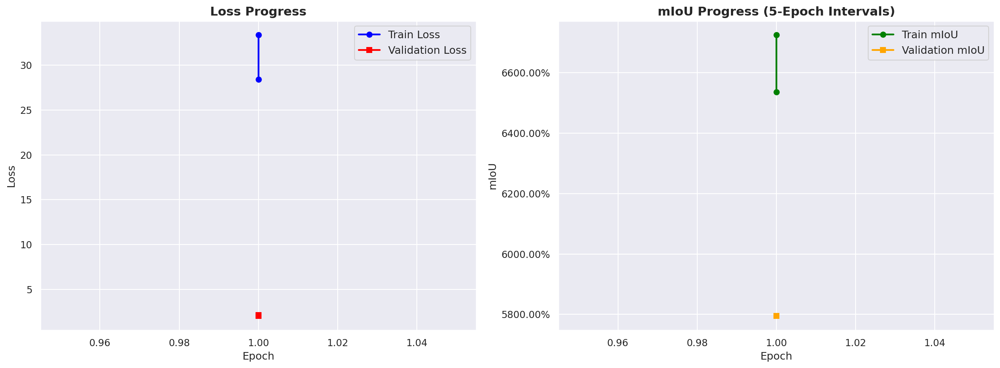

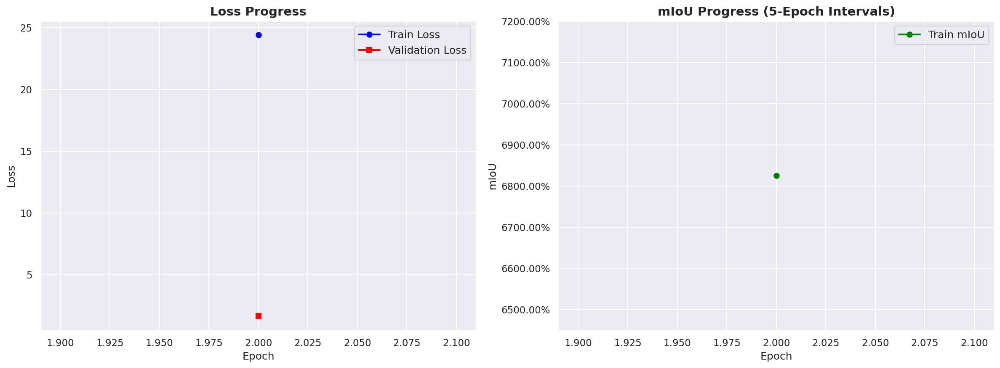

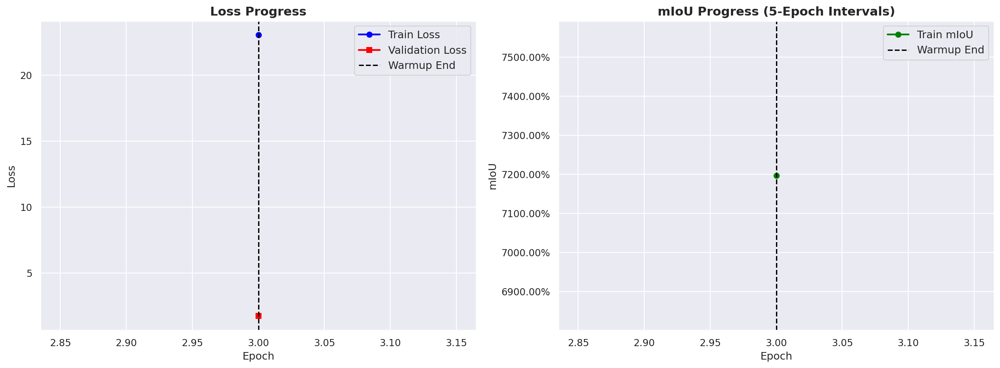

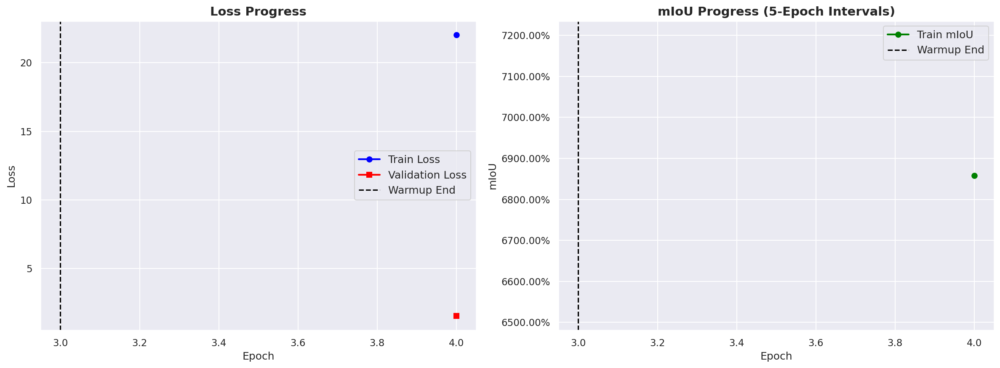

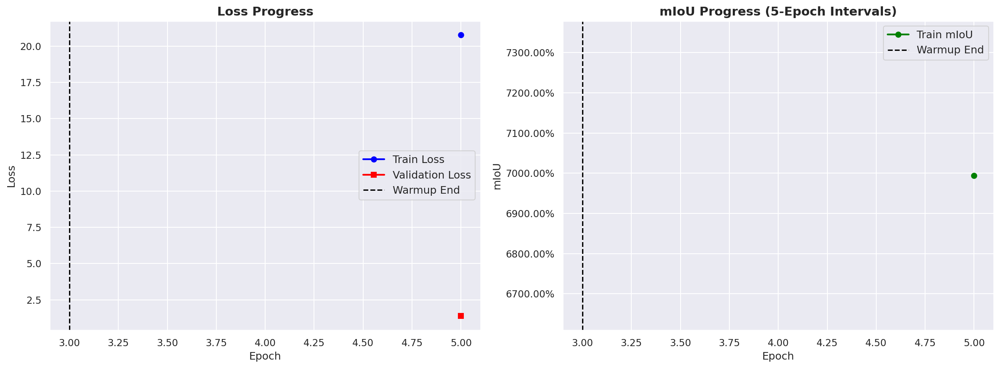

...

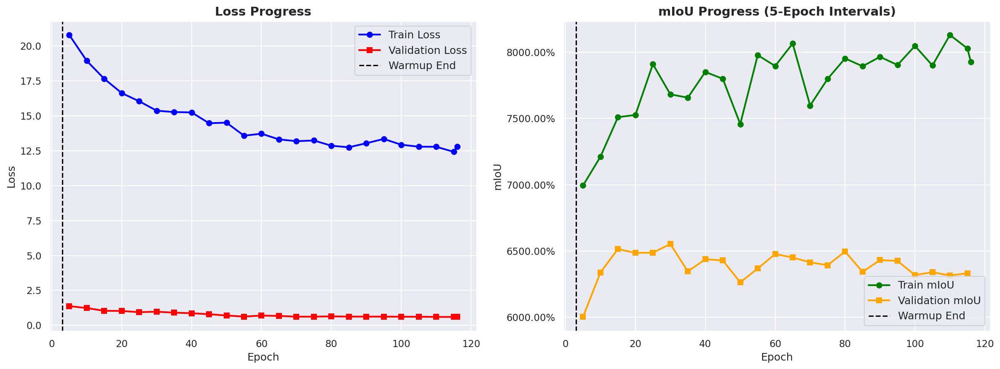

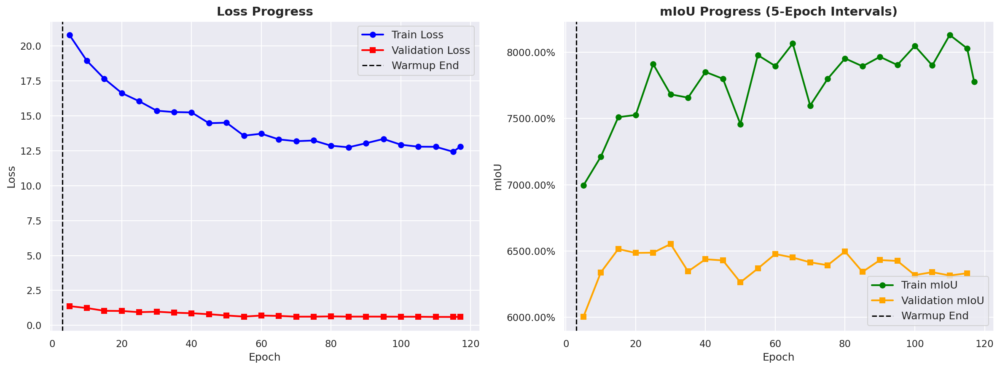

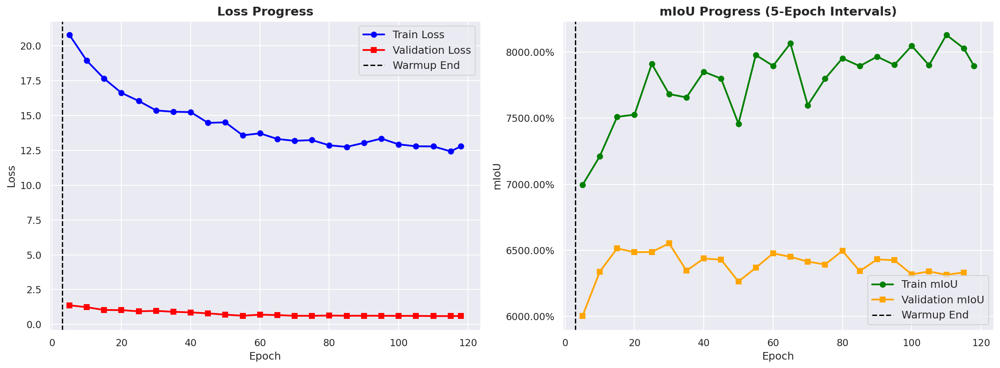

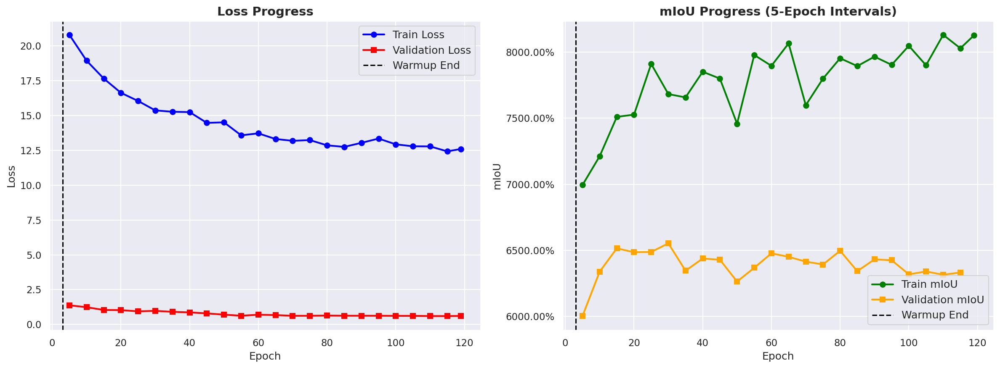

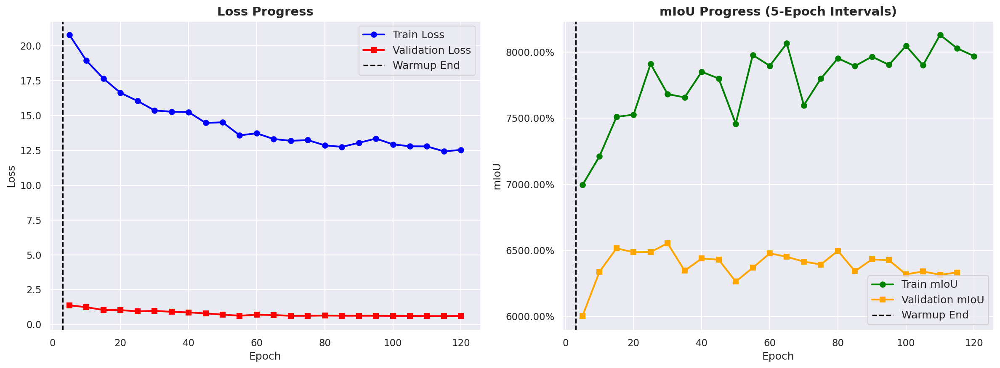

In [12]:
# ============================================================
# STEP 5: TRAINING LOOP
# For: WEPD-Mask2Former (Wavelet-Enhanced Pixel Decoder)
# Target Dataset: KITTI
# Revised for: WEPD Native Inference, Fully Differentiable Boundary Loss,
# Train vs Val Curves, and FP32 Validation.
# ============================================================

import os
import gc
import math
import time
from datetime import timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm import tqdm

# ------------------------------------------------------------
# SAFETY CHECKS & PATH RESOLUTION
# ------------------------------------------------------------
required_globals = [
    "model", "train_loader", "val_loader", "optimizer", "scheduler",
    "set_model_phase", "get_current_phase", "get_optimizer_for_phase", 
    "CHECKPOINT_DIR", "METRICS_DIR", "history", "best_record", "DEVICE", 
    "CLASSES", "IGNORE_INDEX", "GRAD_ACCUM_STEPS", "EPOCHS", 
    "GRAD_CLIP_NORM", "WARMUP_EPOCHS", "FINAL_SAVE_DIR"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    print(f"Warning: Missing globals {missing}. Relying on fallback defaults where possible.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
USE_AMP = globals().get("USE_AMP", torch.cuda.is_available())

USE_SLIDING_WINDOW_VAL = globals().get("USE_SLIDING_WINDOW_VAL", False)
VAL_WINDOW_SIZE = globals().get("VAL_WINDOW_SIZE", (384, 1248))
VAL_WINDOW_STRIDE = globals().get("VAL_WINDOW_STRIDE", (384, 1248))

USE_FOCAL_LOSS = globals().get("USE_FOCAL_LOSS", True)
FOCAL_GAMMA = globals().get("FOCAL_GAMMA", 2.0)
FOCAL_WEIGHT = globals().get("FOCAL_WEIGHT", 1.0)
USE_LOVASZ = globals().get("USE_LOVASZ", True)
LOVASZ_WEIGHT = globals().get("LOVASZ_WEIGHT", 0.5)
USE_BOUNDARY_LOSS = globals().get("USE_BOUNDARY_LOSS", True)
BOUNDARY_LOSS_WEIGHT = globals().get("BOUNDARY_LOSS_WEIGHT", 0.25)

USE_EARLY_STOPPING = False 
MIN_DELTA_MIOU = 0.001

CHECKPOINT_DIR = str(globals().get("CHECKPOINT_DIR", "./checkpoints"))
METRICS_DIR = str(globals().get("METRICS_DIR", "./metrics"))
PLOTS_DIR = str(globals().get("PLOTS_DIR", "./plots"))
FINAL_SAVE_DIR = Path(globals().get("FINAL_SAVE_DIR", "D:/FINAL_SAVE_DIR"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

for d in [CHECKPOINT_DIR, METRICS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ------------------------------------------------------------
# CORRECTED DIFFERENTIABLE LOSS HELPERS
# ------------------------------------------------------------
def compute_focal_loss_step5(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, gamma: float = 2.0, ignore_index: int = 255) -> torch.Tensor:
    ce_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=ignore_index, reduction='none')
    pt = torch.exp(-ce_loss)
    focal_loss = ((1 - pt) ** gamma) * ce_loss
    return focal_loss.mean()

def compute_boundary_target_patched(targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    boundary = torch.zeros_like(targets, dtype=torch.bool)
    valid = (targets != ignore_index)

    boundary[:, :, 1:] |= ((targets[:, :, 1:] != targets[:, :, :-1]) & valid[:, :, 1:] & valid[:, :, :-1])
    boundary[:, 1:, :] |= ((targets[:, 1:, :] != targets[:, :-1, :]) & valid[:, 1:, :] & valid[:, :-1, :])

    return boundary.unsqueeze(1).float()

def compute_soft_boundary_map_patched(semantic_logits: torch.Tensor) -> torch.Tensor:
    probs = F.softmax(semantic_logits.float(), dim=1)
    B, C, H, W = probs.shape
    boundary = torch.zeros((B, 1, H, W), device=probs.device, dtype=probs.dtype)

    dh = torch.abs(probs[:, :, :, 1:] - probs[:, :, :, :-1]).mean(dim=1, keepdim=True)
    boundary[:, :, :, 1:] += dh

    dv = torch.abs(probs[:, :, 1:, :] - probs[:, :, :-1, :]).mean(dim=1, keepdim=True)
    boundary[:, :, 1:, :] += dv

    return boundary.clamp(min=0.0, max=1.0)

def compute_boundary_loss_patched(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    with torch.no_grad():
        target_boundary = compute_boundary_target_patched(dense_targets, ignore_index=ignore_index)
    pred_boundary = compute_soft_boundary_map_patched(semantic_logits)
    return F.smooth_l1_loss(pred_boundary, target_boundary)

def compute_hybrid_loss_step5(outputs, dense_targets, model_ref):
    native_loss = outputs.loss if outputs.loss is not None else torch.tensor(0.0, device=dense_targets.device)
    H, W = dense_targets.shape[1], dense_targets.shape[2]

    if hasattr(model_ref, "refined_semantic_logits"):
        semantic_logits = model_ref.refined_semantic_logits(outputs, target_size=(H, W))
    else:
        mask_preds = outputs.masks_queries_logits
        class_logits = outputs.class_queries_logits
        mask_preds_up = F.interpolate(mask_preds, size=(H, W), mode="bilinear", align_corners=False)
        mask_cls = F.softmax(class_logits, dim=-1)[..., :-1]
        semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds_up.sigmoid())

    if USE_FOCAL_LOSS:
        main_loss = compute_focal_loss_step5(semantic_logits, dense_targets, gamma=FOCAL_GAMMA, ignore_index=IGNORE_INDEX)
        main_weight = FOCAL_WEIGHT
    else:
        main_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
        main_weight = 1.0

    lovasz_loss = torch.tensor(0.0, device=dense_targets.device)
    boundary_loss = torch.tensor(0.0, device=dense_targets.device)

    if "lovasz_softmax_from_logits" in globals() and USE_LOVASZ:
        lovasz_loss = lovasz_softmax_from_logits(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
    
    if USE_BOUNDARY_LOSS:
        boundary_loss = compute_boundary_loss_patched(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)

    total_loss = native_loss + (main_weight * main_loss) + (LOVASZ_WEIGHT * lovasz_loss) + (BOUNDARY_LOSS_WEIGHT * boundary_loss)

    loss_dict = {
        "native_loss": float(native_loss.detach().item()),
        "ce_loss": float(main_loss.detach().item()),
        "lovasz_loss": float(lovasz_loss.detach().item()),
        "boundary_loss": float(boundary_loss.detach().item()),
        "total_loss": float(total_loss.detach().item())
    }
    return total_loss, loss_dict, semantic_logits

# ------------------------------------------------------------
# SLIDING WINDOW INFERENCE
# ------------------------------------------------------------
def sliding_window_inference(model, image, window_size=(384, 1248), stride=(384, 1248), num_classes=19, use_amp=True):
    B, C, H, W = image.shape
    h_crop, w_crop = window_size
    h_stride, w_stride = stride

    ys = [0] if H <= h_crop else list(range(0, H - h_crop + 1, h_stride))
    if ys[-1] != H - h_crop: ys.append(H - h_crop)
    xs = [0] if W <= w_crop else list(range(0, W - w_crop + 1, w_stride))
    if xs[-1] != W - w_crop: xs.append(W - w_crop)

    full_logits = torch.zeros((B, num_classes, H, W), device=image.device, dtype=torch.float32)
    count_map = torch.zeros((B, 1, H, W), device=image.device, dtype=torch.float32)

    for y1 in ys:
        y2 = min(y1 + h_crop, H)
        for x1 in xs:
            x2 = min(x1 + w_crop, W)
            crop = image[:, :, y1:y2, x1:x2]
            with torch.no_grad():
                with torch.autocast(device_type="cuda", enabled=(use_amp and image.is_cuda)):
                    outputs = model(pixel_values=crop)
                    
                    if hasattr(model, "refined_semantic_logits"):
                        crop_logits = model.refined_semantic_logits(outputs, target_size=(y2 - y1, x2 - x1))
                    else:
                        mask_preds = F.interpolate(outputs.masks_queries_logits, size=(y2 - y1, x2 - x1), mode="bilinear", align_corners=False)
                        mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                        crop_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())

            full_logits[:, :, y1:y2, x1:x2] += crop_logits.float()
            count_map[:, :, y1:y2, x1:x2] += 1.0

    return full_logits / count_map.clamp_min(1.0)

# ------------------------------------------------------------
# HELPERS (Self-contained)
# ------------------------------------------------------------
def build_semantic_targets_from_instance_targets(mask_labels, class_labels, image_size, ignore_index=255):
    H, W = image_size
    batch_size = len(mask_labels)
    device = mask_labels[0].device if len(mask_labels) > 0 else DEVICE
    targets = torch.full((batch_size, H, W), fill_value=ignore_index, dtype=torch.long, device=device)

    for b in range(batch_size):
        if class_labels[b].numel() == 0: continue
        for inst_idx, cls_id in enumerate(class_labels[b]):
            cls_id = int(cls_id.item())
            if cls_id == ignore_index: continue
            targets[b][mask_labels[b][inst_idx] > 0.5] = cls_id
    return targets

def compute_metrics(conf_matrix: np.ndarray):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    return {
        "mIoU": float(mIoU), "aAcc": float(aAcc), "mAcc": float(mAcc),
        "iou_per_class": iou_per_class, "acc_per_class": acc_per_class
    }

def fast_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int) -> np.ndarray:
    idx = num_classes * y_true + y_pred
    return np.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)

def get_lr_snapshot(optimizer):
    lrs = [pg["lr"] for pg in optimizer.param_groups]
    if len(lrs) == 1: return 0.0, lrs[0]
    return lrs[0], lrs[1]

def save_checkpoint(path, model, optimizer, scheduler, epoch, global_update_step, best_record, history):
    ckpt = {
        "epoch": epoch,
        "global_update_step": global_update_step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict() if optimizer else None,
        "scheduler_state_dict": scheduler.state_dict() if scheduler else None,
        "best_record": best_record,
        "history": history,
    }
    torch.save(ckpt, path)

# ------------------------------------------------------------
# TRACKERS & HISTORY ALIGNMENT 
# ------------------------------------------------------------
excel_rows = []
best_conf_matrix = None
best_metrics = None

global_update_step = 0
current_phase = get_current_phase(1)

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
total_update_steps = steps_per_epoch * EPOCHS
training_start_time = time.time()

# [PATCH]: Dynamically align the history dictionary to ensure all validation and 
# WEPD tracking keys exist. Fills missing slots to prevent KeyErrors without restarting Step 1.
expected_keys = [
    "train_native_loss", "train_ce_loss", "train_lovasz_loss", "val_ce_loss",
    "train_boundary_loss", "train_macc", "train_aacc", "sgdw_offset_magnitude", 
    "sgdw_dynamic_bound", "epoch_time_sec", "total_training_time_str"
]
for k in expected_keys:
    if k not in history:
        history[k] = []

print(f"Starting Training: {EPOCHS} Epochs")
print(f"Progressive Unfreezing: Active (Early Stopping Disabled)")
print(f"Focal Loss Active: {USE_FOCAL_LOSS}")
print(f"Boundary Loss Active: {USE_BOUNDARY_LOSS}")
print(f"Validation AMP Overridden: FP32 Forced (NaN Fix Applied)")

# ------------------------------------------------------------
# MAIN LOOP
# ------------------------------------------------------------
for epoch in range(1, EPOCHS + 1):
    epoch_start_time = time.time()

    # ------------------------
    # Phase Management
    # ------------------------
    desired_phase = get_current_phase(epoch)
    if desired_phase != current_phase:
        current_phase = desired_phase
        set_model_phase(model, phase=current_phase)
        optimizer = get_optimizer_for_phase(model, current_phase)
        
        if "build_cosine_warmup_scheduler" in globals():
            scheduler = build_cosine_warmup_scheduler(optimizer, WARMUP_EPOCHS * steps_per_epoch, total_update_steps)
        
        total_params = sum(p.numel() for p in model.parameters())
        trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n--- Epoch {epoch}: Transitioned to Phase {current_phase} ---")
        print(f"Trainable params: {trainable_params:,} / {total_params:,}")

        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    # ------------------------
    # Train
    # ------------------------
    model.train()
    optimizer.zero_grad(set_to_none=True)

    train_total_loss_sum = train_native_loss_sum = train_ce_loss_sum = train_lovasz_loss_sum = train_boundary_loss_sum = 0.0
    train_batches = 0
    
    train_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    train_pbar = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False)

    for step, (images, mask_labels, class_labels) in enumerate(train_pbar, start=1):
        images = images.to(DEVICE, non_blocking=True)
        mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
        class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]

        _, _, curr_h, curr_w = images.shape
        dense_targets = build_semantic_targets_from_instance_targets(mask_labels, class_labels, (curr_h, curr_w), IGNORE_INDEX)

        with torch.autocast(device_type="cuda", enabled=(USE_AMP and images.is_cuda)):
            outputs = model(pixel_values=images, mask_labels=mask_labels, class_labels=class_labels)
            total_loss, loss_dict, semantic_logits = compute_hybrid_loss_step5(outputs, dense_targets, model)
            loss = total_loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        train_total_loss_sum += loss_dict["total_loss"]
        train_native_loss_sum += loss_dict["native_loss"]
        train_ce_loss_sum += loss_dict["ce_loss"]
        train_lovasz_loss_sum += loss_dict["lovasz_loss"]
        train_boundary_loss_sum += loss_dict["boundary_loss"]
        train_batches += 1

        with torch.no_grad():
            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                train_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)

        if (step % GRAD_ACCUM_STEPS == 0) or (step == len(train_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            global_update_step += 1

        lr_backbone, lr_head = get_lr_snapshot(optimizer)
        train_pbar.set_postfix(
            loss=f"{train_total_loss_sum / max(1, train_batches):.4f}",
            focal=f"{train_ce_loss_sum / max(1, train_batches):.4f}",
            bound=f"{train_boundary_loss_sum / max(1, train_batches):.4f}",
            lr=f"{lr_head:.2e}"
        )

    train_metrics = compute_metrics(train_conf_matrix)
    train_total_loss = train_total_loss_sum / max(1, train_batches)

    # ------------------------
    # Validation (FP32 Forced for NaN Fix)
    # ------------------------
    model.eval()
    val_ce_loss_sum = 0.0
    val_total_batches = 0
    val_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)

    val_pbar = tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch}/{EPOCHS} [Val]", leave=False)

    with torch.no_grad():
        for images, mask_labels, class_labels in val_pbar:
            images = images.to(DEVICE, non_blocking=True)
            _, _, val_h, val_w = images.shape
            
            mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
            class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
            dense_targets = build_semantic_targets_from_instance_targets(mask_labels, class_labels, (val_h, val_w), IGNORE_INDEX)

            if USE_SLIDING_WINDOW_VAL:
                semantic_logits = sliding_window_inference(model, images, VAL_WINDOW_SIZE, VAL_WINDOW_STRIDE, CLASSES, use_amp=False)
            else:
                with torch.autocast(device_type="cuda", enabled=False):
                    outputs = model(pixel_values=images)
                    
                    if hasattr(model, "refined_semantic_logits"):
                        semantic_logits = model.refined_semantic_logits(outputs, target_size=(val_h, val_w))
                    else:
                        mask_preds = F.interpolate(outputs.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                        semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())

            ce_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
            val_ce_loss_sum += ce_loss.item()
            val_total_batches += 1

            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)

            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                val_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)

            val_metrics_preview = compute_metrics(val_conf_matrix)
            val_pbar.set_postfix(mIoU=f"{val_metrics_preview['mIoU'] * 100:.2f}%")

    val_metrics = compute_metrics(val_conf_matrix)
    val_ce_loss = val_ce_loss_sum / max(1, val_total_batches)

    # ------------------------
    # Bookkeeping & Artifact Export
    # ------------------------
    epoch_time = time.time() - epoch_start_time
    elapsed = time.time() - training_start_time
    eta_str = str(timedelta(seconds=int((elapsed / epoch) * (EPOCHS - epoch))))
    lr_backbone, lr_head = get_lr_snapshot(optimizer)

    # Dictionary Appends (now completely safe)
    history["epoch"].append(epoch)
    history["phase"].append(current_phase)
    history["train_total_loss"].append(train_total_loss)
    history["train_native_loss"].append(train_native_loss_sum / max(1, train_batches))
    history["train_ce_loss"].append(train_ce_loss_sum / max(1, train_batches))
    history["train_lovasz_loss"].append(train_lovasz_loss_sum / max(1, train_batches))
    history["train_boundary_loss"].append(train_boundary_loss_sum / max(1, train_batches))
    history["train_miou"].append(train_metrics["mIoU"] * 100)
    history["train_macc"].append(train_metrics["mAcc"] * 100)
    history["train_aacc"].append(train_metrics["aAcc"] * 100)

    history["val_total_loss"].append(val_ce_loss)
    history["val_ce_loss"].append(val_ce_loss)
    history["val_miou"].append(val_metrics["mIoU"] * 100) 
    history["val_macc"].append(val_metrics["mAcc"] * 100) 
    history["val_aacc"].append(val_metrics["aAcc"] * 100) 
    history["backbone_lr"].append(lr_backbone)
    history["head_lr"].append(lr_head)
    
    # Fill defaults for legacy keys to prevent DataFrame length mismatch in Step 7
    history["sgdw_offset_magnitude"].append(0.0) 
    history["sgdw_dynamic_bound"].append(0.0)
    history["epoch_time_sec"].append(epoch_time)
    history["total_training_time_str"].append(eta_str)

    print(
        f"\nEpoch {epoch}/{EPOCHS} | Phase {current_phase} | Time: {epoch_time:.2f}s | ETA: {eta_str}\n"
        f"Train Loss: {train_total_loss:.4f} | Train mIoU: {train_metrics['mIoU']*100:.2f}%\n"
        f"Val Loss:   {val_ce_loss:.4f} | Val mIoU:   {val_metrics['mIoU']*100:.2f}% | Val aAcc:   {val_metrics['aAcc']*100:.2f}%\n"
        f"LR Backbone: {lr_backbone:.2e} | LR Head: {lr_head:.2e}"
    )

    # Visual Evaluation Curves explicitly saved to FINAL_SAVE_DIR
    if "plot_training_curves" in globals():
        try:
            plot_path = FINAL_SAVE_DIR / f"combined_metrics_progress_epoch_{epoch:03d}.png"
            plot_training_curves(history, str(plot_path))
        except Exception as e:
            print(f"Could not plot evaluation curves: {e}")

    # Checkpoints
    latest_path = os.path.join(CHECKPOINT_DIR, "latest_checkpoint.pt")
    save_checkpoint(latest_path, model, optimizer, scheduler, epoch, global_update_step, best_record, history)

    improved = val_metrics["mIoU"] > (best_record["best_miou"] + MIN_DELTA_MIOU)
    if improved:
        best_record["best_epoch"] = epoch
        best_record["best_miou"] = val_metrics["mIoU"]
        best_record["best_macc"] = val_metrics["mAcc"]
        best_record["best_aacc"] = val_metrics["aAcc"]
        best_conf_matrix = val_conf_matrix.copy()
        best_metrics = val_metrics.copy()
        
        save_checkpoint(best_record["best_path"], model, optimizer, scheduler, epoch, global_update_step, best_record, history)
        print(f"[*] New Best Validation mIoU: {val_metrics['mIoU']*100:.2f}% saved.")

    if (epoch % 5 == 0) or improved:
        if epoch % 5 == 0:
            save_checkpoint(os.path.join(CHECKPOINT_DIR, f"ckpt_epoch_{epoch:03d}.pt"), model, optimizer, scheduler, epoch, global_update_step, best_record, history)
        
        if "visualize_results" in globals():
            try:
                visualize_results(val_loader, model, epoch, QUAL_VIS_DIR, max_images=3)
            except Exception as e:
                pass

# ------------------------------------------------------------
# FINAL SUMMARY & ARTIFACT EXPORT
# ------------------------------------------------------------
print(f"\n--- Training Complete ---")
print(f"Total Time: {str(timedelta(seconds=int(time.time() - training_start_time)))}")
print(f"Best Epoch: {best_record['best_epoch']} | Best mIoU: {best_record['best_miou'] * 100:.2f}%")
BEST_CONF_MATRIX = best_conf_matrix
BEST_METRICS = best_metrics

try:
    final_results = pd.DataFrame([
        {"Metric": "Best Validation mIoU", "Value": f"{best_record['best_miou'] * 100:.2f}%"},
        {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{best_record['best_aacc'] * 100:.2f}%"},
        {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{best_record['best_macc'] * 100:.2f}%"}
    ])
    final_results.to_csv(FINAL_SAVE_DIR / "finalresults_wepd.csv", index=False)
    print(f"Final training statistics exported successfully to {FINAL_SAVE_DIR / 'finalresults_wepd.csv'}")
except Exception as e:
    print(f"Could not save finalresults CSV: {e}")

In [14]:
# ============================================================
# STEP 6: EXPORT RESULTS, PLOTS, CONFUSION MATRIX, FINAL SUMMARY
# Target Architecture: WEPD-Mask2Former (Wavelet-Enhanced Pixel Decoder)
# Target Dataset: KITTI
# Optimized for: RAM-Corruption Bypass, Automated Matrix Reconstruction, 
# Percentage Matrices, Continuous Metric Plotting
# ============================================================

import os
import glob
import json
from pathlib import Path
from datetime import timedelta

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch.nn.functional as F

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "history", "model", "CLASS_NAMES", "CLASSES",
    "CHECKPOINT_DIR", "best_record", "DEVICE"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("D:/FINAL_SAVE_DIR"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Final export directory validated: {FINAL_SAVE_DIR.resolve()}\n")

# ------------------------------------------------------------
# HISTORY SYNC PROTOCOL (BYPASS RAM CORRUPTION)
# ------------------------------------------------------------
print("[*] Synchronizing metrics from disk to prevent RAM mismatches...")
latest_cands = glob.glob(os.path.join(CHECKPOINT_DIR, "latest*.pt"))
if latest_cands:
    try:
        ckpt_latest = torch.load(latest_cands[0], map_location=DEVICE, weights_only=False)
        if "history" in ckpt_latest and len(ckpt_latest["history"].get("epoch", [])) > 0:
            history = ckpt_latest["history"]
            print("[*] Successfully synchronized tracking history from disk.")
    except Exception as e:
        print(f"[!] Warning: Could not sync history from disk: {e}")

# ------------------------------------------------------------
# AUTOMATED MATRIX RECOVERY PROTOCOL
# ------------------------------------------------------------
BEST_CONF_MATRIX = globals().get("best_conf_matrix", globals().get("val_conf_matrix", None))

if BEST_CONF_MATRIX is None and "val_loader" in globals() and "model" in globals():
    print("[!] Confusion matrix missing from RAM. Reconstructing from Best Checkpoint...")
    best_ckpt_path = best_record.get("best_path", os.path.join(CHECKPOINT_DIR, "best_model_sgdw_kitti.pt"))
    
    if os.path.exists(best_ckpt_path):
        ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        model.eval()
        
        reconstructed_cm = np.zeros((CLASSES, CLASSES), dtype=np.int64)
        
        def _fast_confusion_matrix(y_true, y_pred, num_classes):
            idx = num_classes * y_true + y_pred
            return np.bincount(idx, minlength=num_classes**2).reshape(num_classes, num_classes)

        def _build_semantic_targets(mask_labels, class_labels, image_size):
            H, W = image_size
            targets = torch.full((len(mask_labels), H, W), fill_value=IGNORE_INDEX, dtype=torch.long, device=mask_labels[0].device)
            for b in range(len(mask_labels)):
                if class_labels[b].numel() == 0: continue
                for inst_idx, cls_id in enumerate(class_labels[b]):
                    if int(cls_id.item()) == IGNORE_INDEX: continue
                    targets[b][mask_labels[b][inst_idx] > 0.5] = int(cls_id.item())
            return targets
        
        USE_AMP = torch.cuda.is_available()
        pbar = tqdm(val_loader, total=len(val_loader), desc="Reconstructing Metrics", leave=False)
        
        with torch.no_grad():
            for images, mask_labels, class_labels in pbar:
                images = images.to(DEVICE, non_blocking=True)
                _, _, val_h, val_w = images.shape
                
                mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
                class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
                dense_targets = _build_semantic_targets(mask_labels, class_labels, (val_h, val_w))

                scales = [0.75, 1.0, 1.25]
                final_logits = torch.zeros((images.shape[0], CLASSES, val_h, val_w), device=DEVICE, dtype=torch.float32)
                
                for scale in scales:
                    sH, sW = (int(val_h * scale) // 32) * 32, (int(val_w * scale) // 32) * 32 
                    scaled_img = F.interpolate(images, size=(sH, sW), mode='bilinear', align_corners=False)
                    
                    with torch.autocast(device_type="cuda", enabled=USE_AMP):
                        outputs = model(pixel_values=scaled_img)
                        if hasattr(model, "refined_semantic_logits"):
                            logits = model.refined_semantic_logits(outputs, target_size=(val_h, val_w))
                        else:
                            m_preds = F.interpolate(outputs.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                            m_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                            logits = torch.einsum("bqc,bqhw->bchw", m_cls, m_preds.sigmoid())
                        final_logits += logits.float()
                        
                        outputs_f = model(pixel_values=torch.flip(scaled_img, dims=[3]))
                        if hasattr(model, "refined_semantic_logits"):
                            flip_logits = model.refined_semantic_logits(outputs_f, target_size=(val_h, val_w))
                        else:
                            m_preds_f = F.interpolate(outputs_f.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                            m_cls_f = F.softmax(outputs_f.class_queries_logits, dim=-1)[..., :-1]
                            flip_logits = torch.einsum("bqc,bqhw->bchw", m_cls_f, m_preds_f.sigmoid())
                        final_logits += torch.flip(flip_logits, dims=[3]).float()
                        
                semantic_logits = final_logits / (len(scales) * 2)
                
                preds = torch.argmax(semantic_logits, dim=1).cpu().numpy().astype(np.int64)
                targets_np = dense_targets.cpu().numpy().astype(np.int64)
                valid = (targets_np != IGNORE_INDEX)
                if valid.any():
                    reconstructed_cm += _fast_confusion_matrix(targets_np[valid], preds[valid], CLASSES)
                    
        BEST_CONF_MATRIX = reconstructed_cm
        print("[*] Reconstruction Complete! Restoring class-wise scores.")
    else:
        print("[!] Could not locate best checkpoint on disk. Class-wise metrics will remain empty.")

# ------------------------------------------------------------
# BUILD MAIN DATAFRAME
# ------------------------------------------------------------
num_epochs = len(history["epoch"])

def get_hist_col(key, fallback_key=None):
    col = history.get(key, [])
    if len(col) == num_epochs: return col
    if fallback_key and len(history.get(fallback_key, [])) == num_epochs: return history[fallback_key]
    if len(col) > 0:
        return col + [np.nan] * (num_epochs - len(col)) if len(col) < num_epochs else col[:num_epochs]
    return [np.nan] * num_epochs

df = pd.DataFrame({
    "Epoch": get_hist_col("epoch"),
    "Phase": get_hist_col("phase"),
    "Train_Total_Loss": get_hist_col("train_total_loss"),
    "Train_CE_Loss": get_hist_col("train_ce_loss"),
    "Train_Lovasz_Loss": get_hist_col("train_lovasz_loss"),
    "Train_Boundary_Loss": get_hist_col("train_boundary_loss"),
    "Train_mIoU": get_hist_col("train_miou"),
    "Val_Total_Loss": get_hist_col("val_total_loss"),
    "Val_CE_Loss": get_hist_col("val_ce_loss"),
    "Val_mIoU": get_hist_col("val_miou"),
    "Val_mAcc": get_hist_col("val_macc"),
    "Val_aAcc": get_hist_col("val_aacc"),
    "LR_Backbone": get_hist_col("backbone_lr"),
    "LR_Head": get_hist_col("head_lr"),
    "Epoch_Time_sec": get_hist_col("epoch_time_sec"),
})

total_training_time_sec = float(df["Epoch_Time_sec"].dropna().sum()) if not df["Epoch_Time_sec"].isna().all() else 0.0
total_time_str = str(timedelta(seconds=int(total_training_time_sec)))
df["Total_Training_Session_Time"] = total_time_str

# ------------------------------------------------------------
# PREPARE CLASS-WISE DATA
# ------------------------------------------------------------
class_wise_data = []
if BEST_CONF_MATRIX is not None:
    tp = np.diag(BEST_CONF_MATRIX)
    fp = BEST_CONF_MATRIX.sum(axis=0) - tp
    fn = BEST_CONF_MATRIX.sum(axis=1) - tp
    
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    acc_per_class = tp / (tp + fn + 1e-10)
    
    for i, name in enumerate(CLASS_NAMES):
        class_wise_data.append({
            "Class Name": name,
            "IoU (%)": float(iou_per_class[i] * 100),
            "Accuracy (%)": float(acc_per_class[i] * 100)
        })

# ------------------------------------------------------------
# EXPORT FINAL RESULTS CSV & EXCEL
# ------------------------------------------------------------
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val if val > 1.0 else val * 100.0

def get_last_valid(series):
    s = series.dropna()
    if len(s) == 0: return 0.0
    return float(s.iloc[-1])

final_v_acc = safe_pct(get_last_valid(df["Val_aAcc"]))
final_mIoU = safe_pct(get_last_valid(df["Val_mIoU"]))
final_mAcc = safe_pct(get_last_valid(df["Val_mAcc"]))

if "val_miou" in history and len(history["val_miou"]) > 0:
    clean_miou_list = [x for x in history["val_miou"] if not np.isnan(x)]
    if clean_miou_list:
        best_miou_raw = max(clean_miou_list)
        best_idx = history["val_miou"].index(best_miou_raw)
        best_epoch = history["epoch"][best_idx]
        best_miou = safe_pct(best_miou_raw)
    else:
        best_epoch = best_record.get("best_epoch", -1)
        best_miou = safe_pct(best_record.get("best_miou", 0.0))
else:
    best_epoch = best_record.get("best_epoch", -1)
    best_miou = safe_pct(best_record.get("best_miou", 0.0))

final_global_data = [
    {"Metric": "Best Validation mIoU", "Value": f"{best_miou:.2f}%"},
    {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{final_v_acc:.2f}%"},
    {"Metric": "Final Epoch Mean IoU (mIoU)", "Value": f"{final_mIoU:.2f}%"},
    {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{final_mAcc:.2f}%"},
    {"Metric": "Total Training Time", "Value": total_time_str}
]
pd.DataFrame(final_global_data).to_csv(FINAL_SAVE_DIR / "finalresults_wepd_kitti.csv", index=False)

excel_path = FINAL_SAVE_DIR / "Training_Metrics_Report_WEPD_KITTI.xlsx"
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Epoch_Metrics', index=False)
    if class_wise_data:
        pd.DataFrame(class_wise_data).to_excel(writer, sheet_name='Class_Wise_Results', index=False)

# ------------------------------------------------------------
# STANDARD SEPARATE PLOTS (INDIVIDUAL METRICS)
# ------------------------------------------------------------
sns.set_style("whitegrid")

def save_separate_plot(filename, title, ylabel, train_data, val_data=None, label1="Train", label2="Val"):
    plt.figure(figsize=(10, 6))
    
    epochs_range = range(1, len(train_data) + 1)
    train_clean = np.array(train_data, dtype=float)
    
    if not np.isnan(train_clean).all():
        plt.plot(epochs_range, train_clean, label=label1, lw=2)
    
    if val_data is not None:
        val_clean = np.array(val_data, dtype=float)
        if not np.isnan(val_clean).all():
            plt.plot(epochs_range, val_clean, label=label2, lw=2, color='orange')
            
    if "(%)" in ylabel:
        plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}%".format(int(x))))

    plt.title(title, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / f"{filename}.png", dpi=600, bbox_inches='tight')
    plt.close()

train_total_loss = df["Train_Total_Loss"].tolist()
val_total_loss = df["Val_Total_Loss"].tolist()
train_ce_loss = df["Train_CE_Loss"].tolist()
val_ce_loss = df["Val_CE_Loss"].tolist()

def ensure_percentage(series):
    if series.isna().all(): return None
    data = series.tolist()
    return [x * 100 if (x is not None and x <= 1.0) else x for x in data]

train_miou = ensure_percentage(df["Train_mIoU"])
val_miou = ensure_percentage(df["Val_mIoU"])
val_aacc = ensure_percentage(df["Val_aAcc"])
val_macc = ensure_percentage(df["Val_mAcc"])

lr_backbone = df["LR_Backbone"].tolist()
lr_head = df["LR_Head"].tolist()

save_separate_plot("loss_total_comparison", "Total Loss Comparison (WEPD)", "Total Loss", train_total_loss, val_total_loss)
save_separate_plot("loss_ce_comparison", "Cross Entropy Loss Comparison (WEPD)", "CE Loss", train_ce_loss, val_ce_loss)
save_separate_plot("learning_rate_progress", "Progressive Multi-Rate Schedule", "Learning Rate", lr_backbone, lr_head, label1="Backbone LR", label2="Head LR")

save_separate_plot("miou_progress", "Mean IoU (mIoU) Progress", "mIoU (%)", val_miou, train_miou, label1="Val mIoU", label2="Train mIoU")
save_separate_plot("macc_progress", "Mean Class Accuracy (mAcc) Progress", "mAcc (%)", val_macc, label1="Val mAcc")
save_separate_plot("aacc_progress", "Global Pixel Accuracy (aAcc) Progress", "aAcc (%)", val_aacc, label1="Val aAcc")

# ------------------------------------------------------------
# PERCENTAGE-BASED CONFUSION MATRIX
# ------------------------------------------------------------
if BEST_CONF_MATRIX is not None:
    plt.figure(figsize=(18, 14)) 
    
    cm_normalized = BEST_CONF_MATRIX.astype('float') / (BEST_CONF_MATRIX.sum(axis=1)[:, np.newaxis] + 1e-10)
    
    sns.heatmap(
        cm_normalized, annot=True, fmt='.1%', cmap='Blues', 
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, 
        annot_kws={"size": 9}
    ) 
    
    plt.title(f"WEPD Confusion Matrix (Best Epoch {best_epoch})", fontsize=18, fontweight='bold', pad=20)
    plt.ylabel('True Class', fontsize=14)
    plt.xlabel('Predicted Class', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / "confusion_matrix_percentages_wepd_kitti.png", dpi=600, bbox_inches='tight')
    plt.close()

# ------------------------------------------------------------
# FINAL PRINT SUMMARY
# ------------------------------------------------------------
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n" + "-"*60)
print(f"Architecture: Wavelet-Enhanced Pixel Decoder (WEPD)")
print(f"Decoder: Mask2Former (Bipartite Native)")
print(f"Backbone: Swin-Small")
print(f"Total Parameters:      {total_params:,}  ({total_params/1e6:.2f} M)")
print(f"Trainable Parameters:  {trainable_params:,}  ({trainable_params/1e6:.2f} M)")
print(f"-"*60)
print(f"SUCCESS: All artifacts and graphs routed to:\n{FINAL_SAVE_DIR.resolve()}")
print("\n" + "="*60)
print(f"FINAL RESULTS (WEPD Architecture - KITTI)")
print("="*60)
print(f"Best Validation mIoU:           {best_miou:.2f}% (Epoch {best_epoch})")
print(f"Final Epoch Pixel Acc (aAcc):   {final_v_acc:.2f}%")
print(f"Final Epoch Mean IoU (mIoU):    {final_mIoU:.2f}%")
print(f"Final Epoch Mean Class Acc:     {final_mAcc:.2f}%")
print(f"Total Training Time:            {total_time_str}")
print("-" * 60)
print(f"{'CLASS NAME':<20} | {'IoU (%)':<10} | {'Accuracy (%)':<10}")
print("-" * 60)

if class_wise_data:
    for item in class_wise_data:
        print(f"{item['Class Name']:<20} | {item['IoU (%)']:<10.2f} | {item['Accuracy (%)']:<10.2f}")

Final export directory validated: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export

[*] Synchronizing metrics from disk to prevent RAM mismatches...
[*] Successfully synchronized tracking history from disk.

------------------------------------------------------------
Architecture: Wavelet-Enhanced Pixel Decoder (WEPD)
Decoder: Mask2Former (Bipartite Native)
Backbone: Swin-Small
Total Parameters:      69,546,830  (69.55 M)
Trainable Parameters:  68,058,620  (68.06 M)
------------------------------------------------------------
SUCCESS: All artifacts and graphs routed to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export

FINAL RESULTS (WEPD Architecture - KITTI)
Best Validation mIoU:           65.88% (Epoch 26)
Final Epoch Pixel Acc (aAcc):   93.83%
Final Epoch Mean IoU (mIoU):    64.15%
Final Epoch Mean Class Acc:     68.96%
Total Training Time:            1:21:19
---------------------------------

[*] Presentation graph will be exported to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export
[*] Filtered presentation graph saved successfully to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_kitti/Results_Export/presentation_metrics_progress_wepd_kitti.png


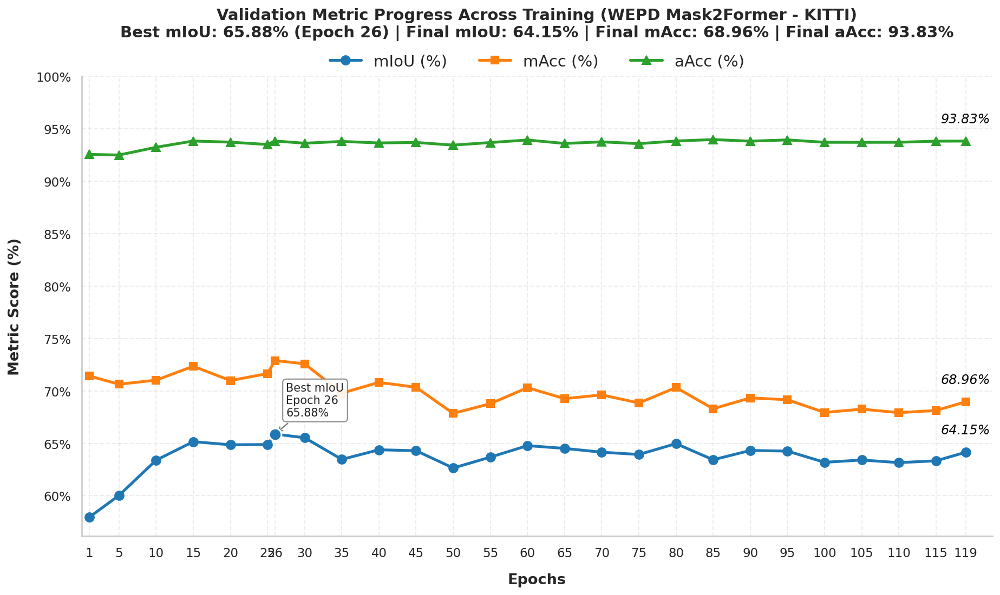

In [15]:
# ============================================================
# STEP 7: PRESENTATION-READY MULTI-METRIC PROGRESS GRAPH
# Target Architecture: WEPD-Mask2Former (Wavelet-Enhanced Pixel Decoder)
# Target Dataset: KITTI
# Optimized for: RAM-Corruption Bypass, Global Path Inheritance, 
# Specific Epoch Intervals, and Strict Percentage Scaling for Publication
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = ["history"]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

if "val_miou" not in history or len(history["val_miou"]) == 0:
    raise ValueError("history['val_miou'] is empty. Run training (Step 5) before Step 7.")

FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("D:/FINAL_SAVE_DIR"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[*] Presentation graph will be exported to: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# PREPARE EPOCHS & DATA (NAN-SAFE RECONSTRUCTION)
# ------------------------------------------------------------
PLOT_INTERVAL = 5

def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val * 100.0 if val <= 1.0 else float(val)

# Isolate valid data points to bypass any NaN padding from previous interruptions
valid_indices = [i for i, v in enumerate(history["val_miou"]) if not pd.isna(v)]
if not valid_indices:
    raise ValueError("[!] No valid validation metrics found to plot.")

actual_epochs = [history["epoch"][i] for i in valid_indices]
clean_miou = [history["val_miou"][i] for i in valid_indices]
clean_macc = [history["val_macc"][i] for i in valid_indices]
clean_aacc = [history["val_aacc"][i] for i in valid_indices]

# Bulletproof Best Epoch Extraction
best_miou_raw = max(clean_miou)
best_idx = clean_miou.index(best_miou_raw)
best_miou = safe_pct(best_miou_raw)
best_miou_epoch = actual_epochs[best_idx]

# Filter epochs to reduce visual clutter: Epoch 1, every nth epoch, best epoch, final epoch
filtered_epochs_set = set([e for e in actual_epochs if e == 1 or e % PLOT_INTERVAL == 0] + [actual_epochs[-1], best_miou_epoch])
filtered_epochs = sorted(list(filtered_epochs_set))

indices = [actual_epochs.index(e) for e in filtered_epochs]

# Extract and convert to percentages for cleaner presentation
miou_scores = [safe_pct(clean_miou[i]) for i in indices]
macc_scores = [safe_pct(clean_macc[i]) for i in indices]
aacc_scores = [safe_pct(clean_aacc[i]) for i in indices]

final_miou = safe_pct(clean_miou[-1])
final_macc = safe_pct(clean_macc[-1])
final_aacc = safe_pct(clean_aacc[-1])
final_x = actual_epochs[-1]

# ------------------------------------------------------------
# PLOT SETUP 
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12.5, 7.5)) 

color_miou = '#1f77b4'  # Blue
color_macc = '#ff7f0e'  # Orange
color_aacc = '#2ca02c'  # Green

ax.plot(filtered_epochs, miou_scores, marker='o', linewidth=2.5, markersize=8, label='mIoU (%)', color=color_miou)
ax.plot(filtered_epochs, macc_scores, marker='s', linewidth=2.5, markersize=7, label='mAcc (%)', color=color_macc)
ax.plot(filtered_epochs, aacc_scores, marker='^', linewidth=2.5, markersize=8, label='aAcc (%)', color=color_aacc)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------
ax.set_xlabel('Epochs', fontsize=13, fontweight='bold', labelpad=12)
ax.set_ylabel('Metric Score (%)', fontsize=13, fontweight='bold', labelpad=12)
ax.set_xticks(filtered_epochs)

# Force the Y-axis to display percent signs natively
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x)}%"))

# ------------------------------------------------------------
# BEST mIoU ANNOTATION 
# ------------------------------------------------------------
ax.scatter(best_miou_epoch, best_miou, s=120, zorder=5, color=color_miou, edgecolors='white', linewidth=1.5)

if best_miou_epoch <= (max(filtered_epochs) * 0.6):
    best_text_x = best_miou_epoch + 1.5
    best_ha = "left"
else:
    best_text_x = best_miou_epoch - 1.5
    best_ha = "right"

ax.annotate(
    f'Best mIoU\nEpoch {best_miou_epoch}\n{best_miou:.2f}%',
    xy=(best_miou_epoch, best_miou),
    xytext=(best_text_x, best_miou + 1.5),
    fontsize=10, ha=best_ha, va='bottom',
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
    arrowprops=dict(arrowstyle='->', color='gray', lw=1.2)
)

# ------------------------------------------------------------
# END-OF-LINE FINAL VALUE ANNOTATIONS (Floating above markers)
# ------------------------------------------------------------
offset_y = 1.5

ax.text(final_x, final_miou + offset_y, f'{final_miou:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_macc + offset_y, f'{final_macc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_aacc + offset_y, f'{final_aacc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')

ax.set_xlim(left=0, right=max(actual_epochs) + (max(actual_epochs) * 0.03))
ax.set_ylim(top=100) 

# ------------------------------------------------------------
# STYLING & LEGEND
# ------------------------------------------------------------
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False, fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.3)
ax.spines['left'].set_linewidth(1.3)

ax.grid(True, linestyle='--', alpha=0.35)

title_main = "Validation Metric Progress Across Training (WEPD Mask2Former - KITTI)"
title_sub = f"Best mIoU: {best_miou:.2f}% (Epoch {best_miou_epoch}) | Final mIoU: {final_miou:.2f}% | Final mAcc: {final_macc:.2f}% | Final aAcc: {final_aacc:.2f}%"

ax.set_title(
    title_main + "\n" + title_sub,
    fontsize=14, fontweight='bold', pad=35
)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
combined_graph_path = FINAL_SAVE_DIR / "presentation_metrics_progress_wepd_kitti.png"
plt.savefig(combined_graph_path, dpi=600, bbox_inches='tight')
print(f"[*] Filtered presentation graph saved successfully to:\n{combined_graph_path.resolve()}")

plt.show()
plt.close()